# Geometra: recomendador de cafeterías en Mérida

**Autor: Aarón Eduardo Arceo Arjona**
___

Trabajo Final del Diplomado en Ciencia de Datos (Módulo 5). El notebook reúne el contexto del sector con datos
del DENUE, la preparación y el análisis exploratorio de las cafeterías y reseñas obtenidas de Google, y el modelo
de recomendación con su evaluación. El modelo es el que usa la aplicación web Locus
(https://geometra-locus.vercel.app).

**Antes de ejecutar**

- Se ejecuta completo con *Entorno de ejecución > Ejecutar todas*, en unos 5 minutos. No requiere GPU ni
  credenciales.
- La sección 0 descarga de Google Drive la carpeta de datos (unos 40 MB). Si la carpeta `Datos_Geometra/` ya está
  junto al notebook, se usa esa.
- Durante la ejecución se descarga de Hugging Face el modelo de *embeddings* (unos 470 MB).
- El sentimiento y los *embeddings* de las 15,685 reseñas se cargan ya calculados. Con `RECALCULAR = True`
  (sección 0) se calculan de nuevo; en CPU tarda alrededor de media hora.
- La extracción de lugares (Google Places API) y de reseñas (Selenium) se documenta en dos notebooks aparte, porque
  requiere una clave de API y un navegador.

**Contenido**

0. Configuración y datos
1. Contexto del sector (DENUE)
2. Preparación de la base de cafeterías
3. Análisis exploratorio de las cafeterías
4. Análisis exploratorio de las reseñas y sentimiento
5. Ingeniería de variables
6. Modelo de recomendación
7. Evaluación y resultados
8. Conclusiones y recomendaciones

## 0. Configuración y datos

Instala solo las bibliotecas que falten (en Colab normalmente ninguna). `ID_DRIVE` y `RECALCULAR` son los únicos
parámetros que se pueden ajustar.

In [1]:
import importlib.util
import subprocess
import sys

PAQUETES = {'geopandas': 'geopandas', 'sentence_transformers': 'sentence-transformers', 'wordcloud': 'wordcloud',
            'gdown': 'gdown', 'seaborn': 'seaborn', 'statsmodels': 'statsmodels'}
faltantes = [pip for modulo, pip in PAQUETES.items() if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *faltantes], check=True, capture_output=True)
print('Bibliotecas instaladas en esta sesión:', ', '.join(faltantes) or 'ninguna')

Bibliotecas instaladas en esta sesión: ninguna


In [2]:
# Parámetros -----------------------------------------------------------------
ID_DRIVE = '1WM18VwFvPEIWJGDBrt8Jndqw3WjfoGgk'   # Datos_Geometra.zip en Google Drive (cualquier persona con el enlace)
RECALCULAR = False                          # True: recalcula sentimiento y embeddings de las reseñas
SEMILLA = 20260923

import os
os.environ.update({'HF_HUB_DISABLE_PROGRESS_BARS': '1', 'HF_HUB_VERBOSITY': 'error',
                   'TRANSFORMERS_VERBOSITY': 'error', 'TOKENIZERS_PARALLELISM': 'false'})

import warnings
warnings.filterwarnings('ignore')   # avisos de versiones de bibliotecas; no afectan los resultados

import json
import re
import unicodedata
import zipfile
from datetime import date
from pathlib import Path

import torch
from transformers import pipeline
from sentence_transformers import SentenceTransformer

import joblib
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
import seaborn as sns
from PIL import Image
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import NearestNeighbors

pd.set_option('display.max_columns', None, 'display.width', None, 'display.max_colwidth', 80)
np.random.seed(SEMILLA)

# Paleta del proyecto
color1 = '#282832'  # texto y contornos
color2 = '#77181e'  # acento principal
color3 = '#a92727'  # acento secundario
color4 = '#c6d6d6'  # relleno neutro
color5 = '#dee7e7'  # fondo

CRS_M = 'EPSG:32616'   # UTM zona 16N, en metros
CVE_MUN_MERIDA = '31050'
print('Bibliotecas importadas.')

Bibliotecas importadas.


In [3]:
def preparar_datos(carpeta='Datos_Geometra', id_drive=ID_DRIVE):
    """Devuelve la carpeta de datos del proyecto.

    Si la carpeta ya existe junto al notebook se usa tal cual; si no, se descarga el
    archivo comprimido desde Google Drive y se descomprime en el directorio actual.
    """
    ruta = Path(carpeta)
    if not ruta.is_dir():
        import gdown
        archivo = gdown.download(id=id_drive, output=f'{carpeta}.zip', quiet=True)
        with zipfile.ZipFile(archivo) as z:
            z.extractall('.')
    return ruta


DATOS = preparar_datos()
SALIDAS = Path('salidas')   # lo que genera el notebook; la carpeta de datos no se modifica
SALIDAS.mkdir(exist_ok=True)

for f in sorted(DATOS.iterdir()):
    print(f'{f.name:36s} {f.stat().st_size / 1e6:5.1f} MB')

agebs_merida_urbanas.gpkg              0.9 MB
denue_merida_722_2024_2026.csv         4.6 MB
places_malla_merida.csv                5.5 MB
places_merida_clean.csv                2.1 MB
reviews_embeddings.npz                24.2 MB
reviews_scraped.csv                    5.2 MB
reviews_sentiment.csv                  0.4 MB
taza_wordcloud.png                     0.1 MB


## 1. Contexto del sector (DENUE)

Establecimientos del subsector 722 (preparación de alimentos y bebidas) en las AGEB urbanas de Mérida, en los
cortes de noviembre de 2024, mayo de 2025 y mayo de 2026. El segmento de interés es el código 722515 (cafeterías,
fuentes de sodas, neverías y refresquerías). Solo se comparan estos cortes porque en 2024 el INEGI rehízo el
registro, y la comparación se hace con conteos agregados.

La copia de datos trae solo Mérida; los filtros se conservan para que el código funcione igual con los archivos
originales del INEGI.

In [4]:
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.7, 'grid.color': color4, 'axes.axisbelow': True,
    'text.color': color1, 'axes.labelcolor': color1, 'axes.edgecolor': color1,
    'xtick.color': color1, 'ytick.color': color1,
})


def mezcla(c_a, c_b, p):
    """Tono intermedio entre dos colores (p = proporción de c_b), para no salir de la paleta."""
    a, b = np.array(mcolors.to_rgb(c_a)), np.array(mcolors.to_rgb(c_b))
    return mcolors.to_hex((1 - p) * a + p * b)


NEUTRO_MEDIO = mezcla(color4, color1, 0.4)
SIN_CLASIFICAR = mezcla(color5, '#ffffff', 0.6)
ANIOS = ['2024', '2025', '2026']
SEG = '722515'
SEG_NOMBRE = 'Cafeterías, fuentes de sodas, neverías y refresquerías (722515)'

# AGEB urbanas de Mérida (referencia territorial de todo el notebook)
agebs = gpd.read_file(DATOS / 'agebs_merida_urbanas.gpkg')
agebs_merida = (agebs[(agebs['cve_mun'] == CVE_MUN_MERIDA) & (agebs['ambito'] == 'U')][['cvegeo', 'geometry']]
                .to_crs(CRS_M).reset_index(drop=True))
mer_u = agebs_merida.copy()
silueta = mer_u.dissolve().geometry.iloc[0]
XLIM = (mer_u.total_bounds[0] - 500, mer_u.total_bounds[2] + 500)
YLIM = (mer_u.total_bounds[1] - 500, mer_u.total_bounds[3] + 500)

# DENUE: subsector 722 en el municipio de Mérida, asignado a su AGEB por ubicación
denue = pd.read_csv(DATOS / 'denue_merida_722_2024_2026.csv', dtype=str)
d = denue[(denue['cve_mun'] == '050') & denue['anio'].isin(ANIOS) & denue['codigo_act'].str.startswith('722')]
gd = gpd.GeoDataFrame(d, geometry=gpd.points_from_xy(d['longitud'].astype(float), d['latitud'].astype(float)),
                      crs='EPSG:4326').to_crs(CRS_M)
gd = gpd.sjoin(gd, mer_u.rename(columns={'cvegeo': 'ageb_u'}), predicate='within', how='left')
gd = gd[gd['ageb_u'].notna()].copy()   # solo lo que cae en una AGEB urbana
gd['es_seg'] = gd['codigo_act'].eq(SEG)
seg = gd[gd['es_seg']].copy()

print(f'AGEB urbanas de Mérida: {len(mer_u)}')
print(gd.groupby('anio').agg(subsector_722=('id', 'size'), seg_722515=('es_seg', 'sum')))

AGEB urbanas de Mérida: 541
      subsector_722  seg_722515
anio                           
2024           7517         870
2025           7827         937
2026           7918         956


### Composición del subsector en 2026

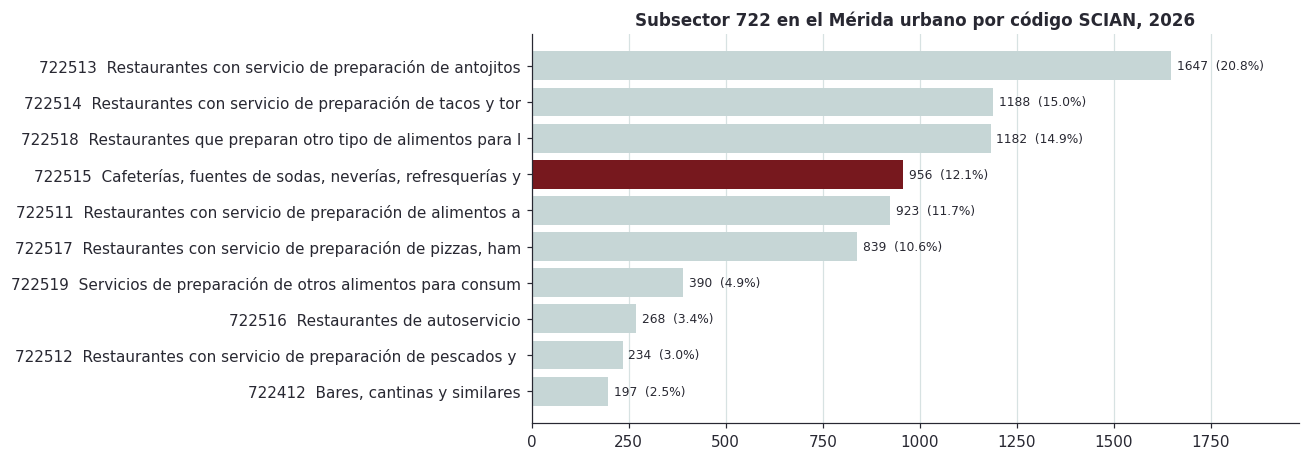

,n,descripcion,%
codigo_act,,,
722513,1647,Restaurantes con servicio de preparación de antojitos,20.8
722514,1188,Restaurantes con servicio de preparación de tacos y tor,15.0
722518,1182,Restaurantes que preparan otro tipo de alimentos para l,14.9
722515,956,"Cafeterías, fuentes de sodas, neverías, refresquerías y",12.1
722511,923,Restaurantes con servicio de preparación de alimentos a,11.7
722517,839,"Restaurantes con servicio de preparación de pizzas, ham",10.6
722519,390,Servicios de preparación de otros alimentos para consum,4.9
722516,268,Restaurantes de autoservicio,3.4
722512,234,Restaurantes con servicio de preparación de pescados y,3.0


In [5]:
comp = (gd[gd['anio'] == '2026'].groupby('codigo_act')
        .agg(n=('id', 'size'), descripcion=('nombre_act', 'first'))
        .sort_values('n', ascending=False))
comp['%'] = (comp['n'] / comp['n'].sum() * 100).round(1)
comp['descripcion'] = comp['descripcion'].str.slice(0, 55)

fig, ax = plt.subplots(figsize=(9, 4.6))
top10 = comp.head(10).iloc[::-1]
ax.barh([f'{c}  {t}' for c, t in zip(top10.index, top10['descripcion'])], top10['n'],
        color=[color2 if c == SEG else color4 for c in top10.index])
for y, (n, p) in enumerate(zip(top10['n'], top10['%'])):
    ax.text(n + 15, y, f'{n}  ({p}%)', va='center', fontsize=8)
ax.set_title('Subsector 722 en el Mérida urbano por código SCIAN, 2026')
ax.set_xlim(0, comp['n'].max() * 1.2)
ax.grid(axis='y')
plt.show()
comp

### Crecimiento 2024 a 2026

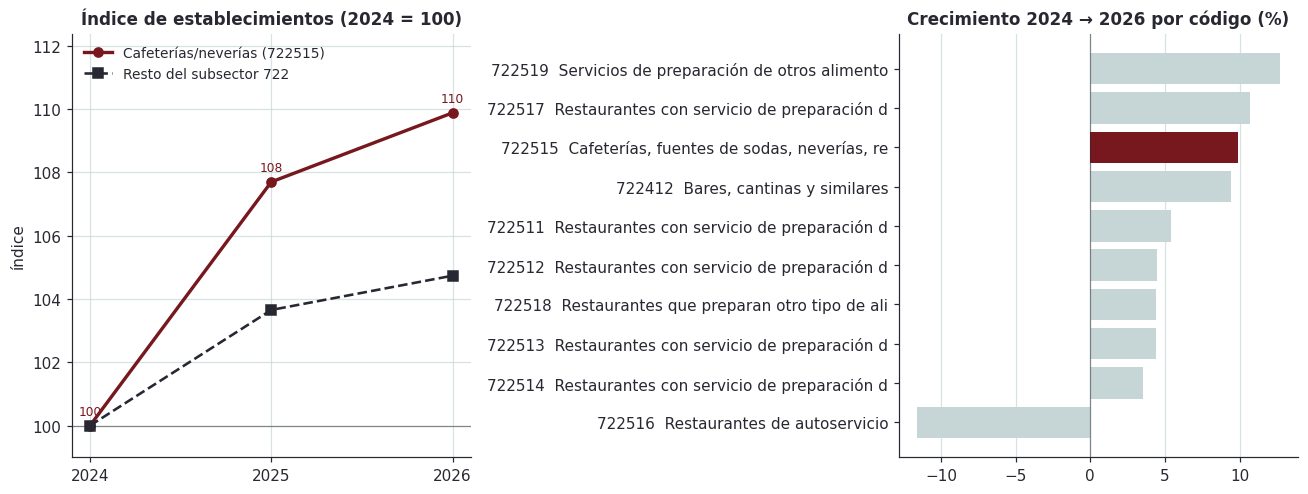

es_seg  Resto del subsector 722  \
anio                              
2024                       6647   
2025                       6890   
2026                       6962   

es_seg  Cafeterías, fuentes de sodas, neverías y refresquerías (722515)  \
anio                                                                      
2024                                                                870   
2025                                                                937   
2026                                                                956   

es_seg  Subsector 722 (total)  
anio                           
2024                     7517  
2025                     7827  
2026                     7918  

Crecimiento 2024-2026:  722515 = +9.9%   resto 722 = +4.7%   total 722 = +5.3%


In [6]:
serie = (gd.groupby(['anio', 'es_seg']).size().unstack()
         .rename(columns={False: 'Resto del subsector 722', True: SEG_NOMBRE}))
serie['Subsector 722 (total)'] = serie.sum(axis=1)
idx = serie / serie.iloc[0] * 100

crec_cod = gd.groupby(['codigo_act', 'anio']).size().unstack()
crec_cod = crec_cod[crec_cod['2026'] >= 100]
crec_cod['crec_%'] = ((crec_cod['2026'] / crec_cod['2024'] - 1) * 100).round(1)
crec_cod['desc'] = gd.groupby('codigo_act')['nombre_act'].first().str.slice(0, 42)
crec_cod = crec_cod.sort_values('crec_%')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
ax1.plot(ANIOS, idx[SEG_NOMBRE], 'o-', color=color2, lw=2.2, label='Cafeterías/neverías (722515)')
ax1.plot(ANIOS, idx['Resto del subsector 722'], 's--', color=color1, lw=1.7, label='Resto del subsector 722')
ax1.axhline(100, color=color1, lw=0.8, alpha=0.5)
ax1.set_title('Índice de establecimientos (2024 = 100)')
ax1.set_ylabel('índice')
ax1.set_ylim(99, idx[[SEG_NOMBRE, 'Resto del subsector 722']].to_numpy().max() + 2.5)
ax1.legend(frameon=False, fontsize=9, loc='upper left')
for a in ANIOS:
    ax1.annotate(f'{idx.loc[a, SEG_NOMBRE]:.0f}', (a, idx.loc[a, SEG_NOMBRE]),
                 textcoords='offset points', xytext=(0, 7), ha='center', fontsize=8, color=color2)

ax2.barh([f'{c}  {t}' for c, t in zip(crec_cod.index, crec_cod['desc'])], crec_cod['crec_%'],
         color=[color2 if c == SEG else color4 for c in crec_cod.index])
ax2.axvline(0, color=color1, lw=0.8, alpha=0.5)
ax2.set_title('Crecimiento 2024 → 2026 por código (%)')
ax2.grid(axis='y')
fig.tight_layout()
plt.show()

print(serie.astype(int))
print('\nCrecimiento 2024-2026:  722515 = {:+.1f}%   resto 722 = {:+.1f}%   total 722 = {:+.1f}%'.format(
    idx[SEG_NOMBRE].iloc[-1] - 100, idx['Resto del subsector 722'].iloc[-1] - 100,
    idx['Subsector 722 (total)'].iloc[-1] - 100))

### Colonias con más establecimientos (2026)

In [7]:
g26 = gd[gd['anio'] == '2026']
colonias = pd.concat([g26.groupby('nomb_asent').size().rename('n_722'),
                      g26[g26['es_seg']].groupby('nomb_asent').size().rename('n_722515')], axis=1).fillna(0).astype(int)
colonias['%_seg'] = (colonias['n_722515'] / colonias['n_722'] * 100).round(1)
share_ciudad = g26['es_seg'].mean() * 100
print(f'Peso del segmento 722515 en toda la ciudad: {share_ciudad:.1f}%')
colonias.sort_values('n_722515', ascending=False).head(10)

Peso del segmento 722515 en toda la ciudad: 12.1%


,n_722,n_722515,%_seg
nomb_asent,,,
CENTRO,1303,215,16.5
CIUDAD CAUCEL,341,29,8.5
LAS AMERICAS,153,23,15.0
FRANCISCO DE MONTEJO,167,22,13.2
JUAN PABLO II,155,14,9.0
ALTABRISA,38,13,34.2
SAN RAMÓN NORTE,38,13,34.2
MEXICO,50,10,20.0
GARCÍA GINERÉS,59,10,16.9


### Distribución en la ciudad por AGEB (2026)

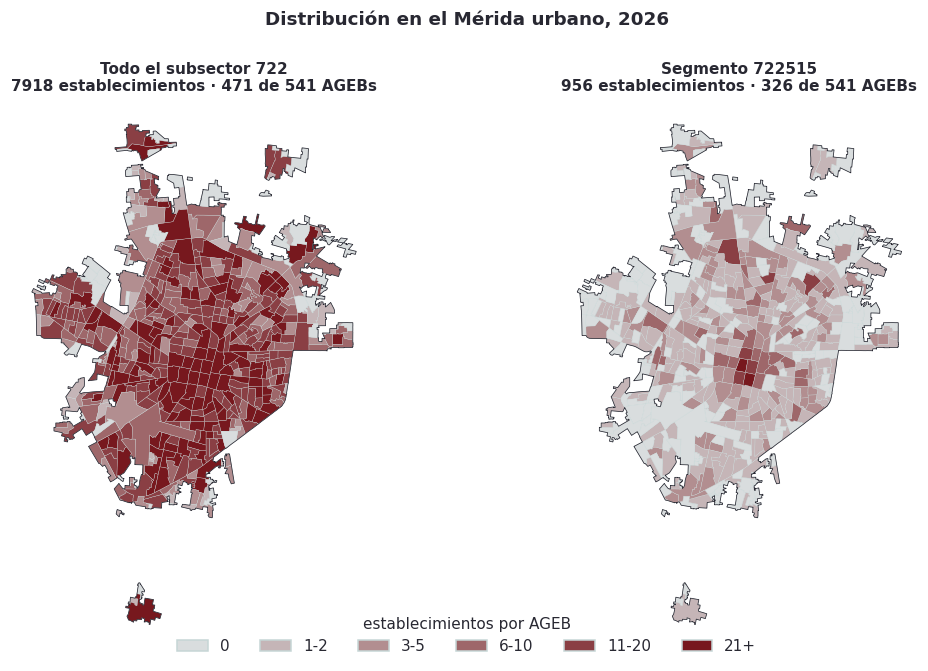

In [8]:
BINS = [-0.1, 0.5, 2.5, 5.5, 10.5, 20.5, 1e9]
ETIQ = ['0', '1-2', '3-5', '6-10', '11-20', '21+']
CMAP = mcolors.LinearSegmentedColormap.from_list('c', [color5, color2])
COLORES = {e: mcolors.to_hex(CMAP(t)) for e, t in zip(ETIQ, np.linspace(0.05, 1, len(ETIQ)))}


def colores_conteo(valores, bins=BINS, etiq=ETIQ):
    """Color de cada AGEB según el rango de su conteo de establecimientos."""
    cls = pd.cut(valores, bins=bins, labels=etiq).astype(str)
    return [COLORES.get(c, list(COLORES.values())[0]) for c in cls]


def limpia_mapa(ax):
    """Encuadre común de los mapas: extensión de la ciudad, sin ejes ni rejilla."""
    ax.set_xlim(XLIM)
    ax.set_ylim(YLIM)
    ax.set_aspect('equal')
    ax.grid(False)
    ax.set_axis_off()


def por_ageb(puntos):
    """Conteo de puntos por AGEB, alineado con el orden de `mer_u` (0 si no hay)."""
    c = puntos['ageb_u'].value_counts()
    return mer_u['cvegeo'].map(c).fillna(0).astype(int)


mer_u['n722_26'] = por_ageb(g26).values
mer_u['nseg_26'] = por_ageb(g26[g26['es_seg']]).values

fig, axs = plt.subplots(1, 2, figsize=(11, 5.8))
for ax, col_, tit in [(axs[0], 'n722_26', 'Todo el subsector 722'), (axs[1], 'nseg_26', 'Segmento 722515')]:
    mer_u.plot(ax=ax, color=colores_conteo(mer_u[col_]), edgecolor=color4, linewidth=0.2)
    gpd.GeoSeries([silueta], crs=CRS_M).boundary.plot(ax=ax, color=color1, linewidth=0.5)
    limpia_mapa(ax)
    ax.set_title(f'{tit}\n{int(mer_u[col_].sum())} establecimientos · '
                 f'{int((mer_u[col_] > 0).sum())} de {len(mer_u)} AGEBs', fontsize=10)
handles = [Patch(facecolor=COLORES[e], edgecolor=color4, label=e) for e in ETIQ]
fig.legend(handles=handles, title='establecimientos por AGEB', loc='lower center', ncol=6,
           frameon=False, bbox_to_anchor=(0.5, -0.03))
fig.suptitle('Distribución en el Mérida urbano, 2026', y=1.0, fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()

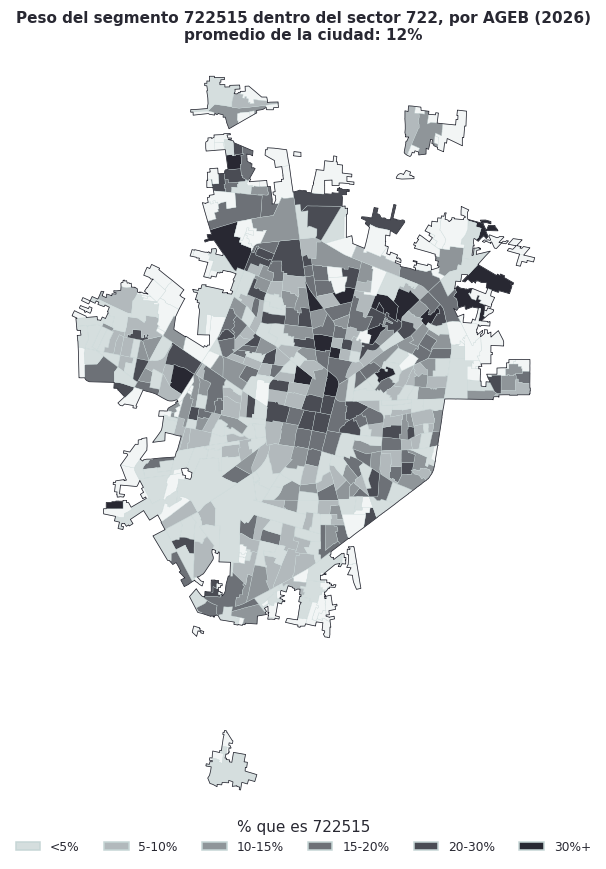

In [9]:
# Peso de 722515 dentro del subsector, solo en AGEB con al menos 4 establecimientos (evita proporciones inestables)
mer_u['share_seg'] = np.where(mer_u['n722_26'] >= 4, mer_u['nseg_26'] / mer_u['n722_26'] * 100, np.nan)
SB = [-0.1, 5, 10, 15, 20, 30, 1e9]
SE = ['<5%', '5-10%', '10-15%', '15-20%', '20-30%', '30%+']
SCMAP = mcolors.LinearSegmentedColormap.from_list('s', [color5, color1])
SCOL = {e: mcolors.to_hex(SCMAP(t)) for e, t in zip(SE, np.linspace(0.05, 1, len(SE)))}

cls = pd.cut(mer_u['share_seg'], bins=SB, labels=SE).astype('object')
cols = [SCOL[c] if isinstance(c, str) and c in SCOL else SIN_CLASIFICAR for c in cls]

fig, ax = plt.subplots(figsize=(7.6, 8))
mer_u.plot(ax=ax, color=cols, edgecolor=color4, linewidth=0.2)
gpd.GeoSeries([silueta], crs=CRS_M).boundary.plot(ax=ax, color=color1, linewidth=0.5)
limpia_mapa(ax)
ax.set_title(f'Peso del segmento 722515 dentro del sector 722, por AGEB (2026)\n'
             f'promedio de la ciudad: {share_ciudad:.0f}%', fontsize=10)
ax.legend(handles=[Patch(facecolor=SCOL[e], edgecolor=color4, label=e) for e in SE], title='% que es 722515',
          loc='upper center', bbox_to_anchor=(0.5, -0.01), ncol=6, frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

### Expansión del segmento 722515 y tamaño de los establecimientos

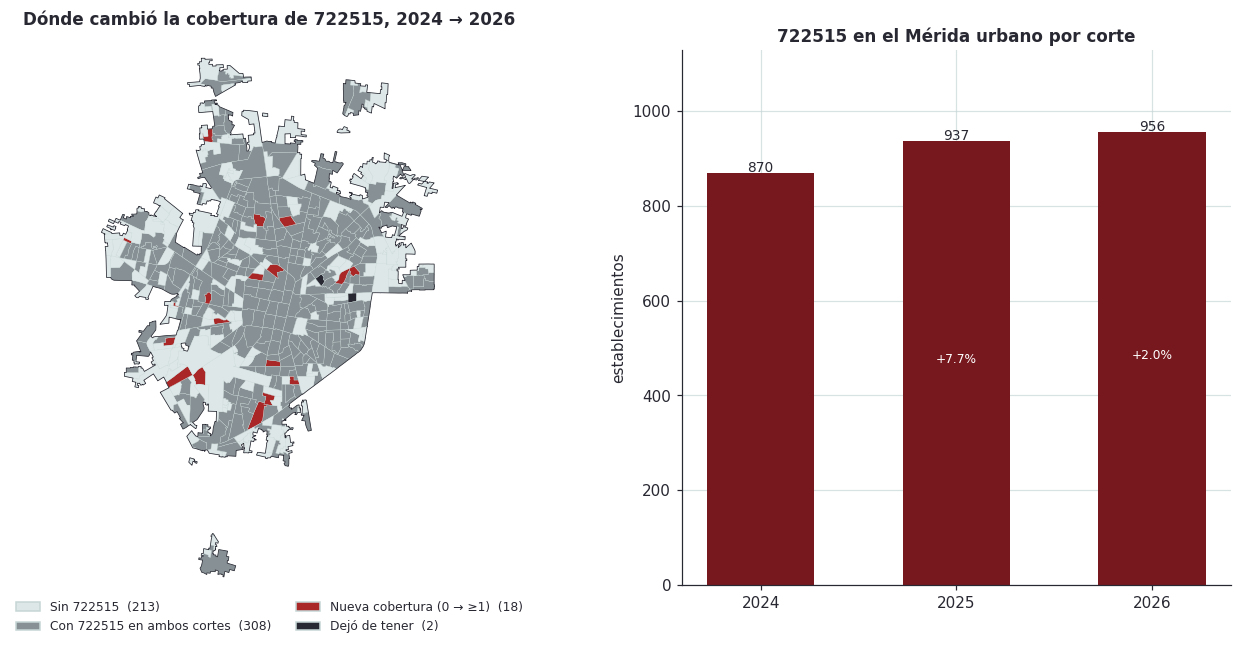

cambio
Con 722515 en ambos cortes    308
Sin 722515                    213
Nueva cobertura (0 → ≥1)       18
Dejó de tener                   2
Name: count, dtype: int64


In [10]:
mer_u['nseg_24'] = por_ageb(seg[seg['anio'] == '2024']).values
mer_u['nseg_26b'] = por_ageb(seg[seg['anio'] == '2026']).values


def clase(r):
    """Clasifica una AGEB según si tenía establecimientos 722515 en 2024 y en 2026."""
    a, b = r['nseg_24'] > 0, r['nseg_26b'] > 0
    return ('Con 722515 en ambos cortes' if a and b else
            'Nueva cobertura (0 → ≥1)' if b else
            'Dejó de tener' if a else 'Sin 722515')


mer_u['cambio'] = mer_u.apply(clase, axis=1)
orden = ['Sin 722515', 'Con 722515 en ambos cortes', 'Nueva cobertura (0 → ≥1)', 'Dejó de tener']
cc = {'Sin 722515': color5, 'Con 722515 en ambos cortes': NEUTRO_MEDIO,
      'Nueva cobertura (0 → ≥1)': color3, 'Dejó de tener': color1}
cnt = mer_u['cambio'].value_counts()

fig, (axm, axb) = plt.subplots(1, 2, figsize=(12, 6), gridspec_kw={'width_ratios': [1.15, 1]})
mer_u.plot(ax=axm, color=[cc[v] for v in mer_u['cambio']], edgecolor=color4, linewidth=0.2)
gpd.GeoSeries([silueta], crs=CRS_M).boundary.plot(ax=axm, color=color1, linewidth=0.5)
limpia_mapa(axm)
axm.set_title('Dónde cambió la cobertura de 722515, 2024 → 2026')
axm.legend(handles=[Patch(facecolor=cc[o], edgecolor=color4, label=f'{o}  ({int(cnt.get(o, 0))})') for o in orden],
           loc='upper center', bbox_to_anchor=(0.5, -0.01), ncol=2, frameon=False, fontsize=8)

s_seg = serie[SEG_NOMBRE]
axb.bar(ANIOS, s_seg.values, color=color2, width=0.55)
for a, v in zip(ANIOS, s_seg.values):
    axb.text(a, v + 3, f'{int(v)}', ha='center', fontsize=9)
axb.set_title('722515 en el Mérida urbano por corte')
axb.set_ylabel('establecimientos')
axb.set_ylim(0, s_seg.max() * 1.18)
for a, b in zip(ANIOS, ANIOS[1:]):
    axb.text(b, s_seg[b] / 2, f'{(s_seg[b] / s_seg[a] - 1) * 100:+.1f}%', ha='center', fontsize=8, color='white')
fig.tight_layout()
plt.show()
print(cnt)

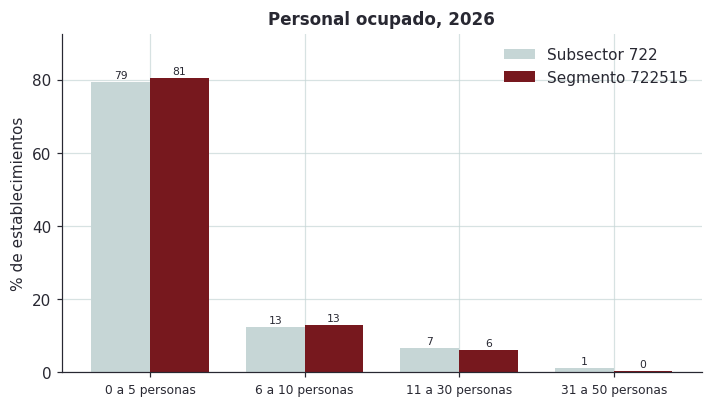

,Subsector 722,Segmento 722515
per_ocu,,
0 a 5 personas,79.5,80.5
6 a 10 personas,12.5,13.0
11 a 30 personas,6.6,6.2
31 a 50 personas,1.1,0.3


In [11]:
ORD = ['0 a 5 personas', '6 a 10 personas', '11 a 30 personas', '31 a 50 personas', '51 a 100 personas']
tam = pd.DataFrame({
    'Subsector 722': g26['per_ocu'].value_counts(normalize=True),
    'Segmento 722515': g26[g26['es_seg']]['per_ocu'].value_counts(normalize=True),
}) * 100
tam = tam.reindex([o for o in ORD if o in tam.index]).fillna(0)
tam = tam[tam.max(axis=1) >= 0.5]   # solo categorías con presencia real

fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(len(tam))
w = 0.38
ax.bar(x - w / 2, tam['Subsector 722'], w, color=color4, label='Subsector 722')
ax.bar(x + w / 2, tam['Segmento 722515'], w, color=color2, label='Segmento 722515')
ax.set_xticks(x)
ax.set_xticklabels(tam.index, fontsize=8)
ax.set_ylabel('% de establecimientos')
ax.set_title('Personal ocupado, 2026')
ax.set_ylim(0, tam.to_numpy().max() * 1.15)
ax.legend(frameon=False)
for i, (a, b) in enumerate(zip(tam['Subsector 722'], tam['Segmento 722515'])):
    ax.text(i - w / 2, a + 1, f'{a:.0f}', ha='center', fontsize=7)
    ax.text(i + w / 2, b + 1, f'{b:.0f}', ha='center', fontsize=7)
plt.show()
tam.round(1)

## 2. Preparación de la base de cafeterías

La base cruda (`places_malla_merida.csv`) viene de consultar Google Places en una malla de 420 celdas de 1 km
sobre la mancha urbana, con los tipos `cafe`, `coffee_shop` e `ice_cream_shop`; la extracción se documenta en un
notebook aparte. Aquí se depura en orden: ubicación, duplicados, estatus del negocio y relevancia del tipo.

In [12]:
BUFFER_MANCHA_M = 200.0   # margen sobre la mancha urbana, el mismo que se usó en la malla de búsqueda
mancha_urbana = agebs_merida.union_all().buffer(BUFFER_MANCHA_M)

places_raw = pd.read_csv(DATOS / 'places_malla_merida.csv', dtype={'celda_id': str, 'place_id': str})
print(f'Filas leídas: {len(places_raw)}')
places_raw = places_raw[places_raw['place_id'].notna()].copy()
print(f'Con lugar encontrado (sin celdas vacías): {len(places_raw)}')

places_geo = gpd.GeoDataFrame(
    places_raw, geometry=gpd.points_from_xy(places_raw['lon_google'], places_raw['lat_google']), crs='EPSG:4326',
).to_crs(CRS_M)
dentro_mancha = places_geo.geometry.within(mancha_urbana)
print(f'Fuera de la mancha urbana (+{BUFFER_MANCHA_M:.0f} m): {(~dentro_mancha).sum()}')
places_geo = places_geo[dentro_mancha].copy()

# Un mismo lugar aparece en varias celdas por el traslape de los círculos de búsqueda
n_repetidos = places_geo['place_id'].duplicated().sum()
places_clean = places_geo.groupby('place_id', as_index=False).first().drop(columns='geometry')
print(f'Duplicados por traslape de celdas: {n_repetidos}')

# Ficha duplicada en el propio Google Maps: mismo nombre y coordenada, distinto place_id (se queda la de más reseñas)
places_clean['_lat_r'] = places_clean['lat_google'].round(4)
places_clean['_lon_r'] = places_clean['lon_google'].round(4)
places_clean = places_clean.sort_values('n_resenas', ascending=False, na_position='last')
antes = len(places_clean)
places_clean = (places_clean.drop_duplicates(subset=['nombre_google', '_lat_r', '_lon_r'], keep='first')
                .drop(columns=['_lat_r', '_lon_r']))
print(f'Fichas duplicadas en Google Maps: {antes - len(places_clean)}')
print(f'Lugares únicos dentro de la mancha urbana: {len(places_clean)}')

Filas leídas: 4288
Con lugar encontrado (sin celdas vacías): 4202
Fuera de la mancha urbana (+200 m): 147
Duplicados por traslape de celdas: 1518
Fichas duplicadas en Google Maps: 1
Lugares únicos dentro de la mancha urbana: 2536


In [13]:
fuera_por_status = places_clean['business_status'] != 'OPERATIONAL'
print(f'No operativos (cierre temporal o definitivo): {fuera_por_status.sum()}')
places_clean = places_clean[~fuera_por_status].copy()

# Tipos que se excluyen siempre (incluye ice_cream_shop: el alcance son cafeterías y postres, no neverías)
TIPOS_EXCLUIR_DURO = {
    'store', 'grocery_store', 'convenience_store', 'meal_delivery', 'catering_service',
    'service', 'hotel', 'gym', 'furniture_store', 'museum', 'florist',
    'general_contractor', 'supplier', 'manufacturer', 'garden_center',
    'sports_complex', 'wholesaler', 'cultural_center',
    'association_or_organization', 'coworking_space', 'internet_cafe', 'ice_cream_shop',
}
# Tipos que se excluyen salvo que el lugar también figure como cafetería (validado a mano)
TIPOS_EXCLUIR_CON_RESCATE = {'food_store', 'food', 'bar', 'dessert_restaurant', 'coffee_roastery', 'cake_shop'}
PALABRAS_RESTAURANTE_ESPECIFICO = ['taco', 'pizza', 'mexican', 'italian', 'french', 'korean',
                                   'lebanese', 'hamburger', 'vegetarian', 'vegan', 'family', 'fast_food']
PLACE_IDS_EXCLUIR_MANUAL = {
    'ChIJDc7FcAlzVo8Rmf5onSVVIJA',  # taquería
    'ChIJ_7yIt7J2Vo8ROAqvR1B2Ivc',  # restaurante de hotel
}


def tiene_tipo_cafe(types_str):
    """True si 'cafe' o 'coffee_shop' aparece como tipo exacto ('internet_cafe' no cuenta)."""
    return bool(set(str(types_str).split(',')) & {'cafe', 'coffee_shop'})


es_cafe_por_types = places_clean['types'].apply(tiene_tipo_cafe)
fuera_por_tipo = (places_clean['primary_type'].isin(TIPOS_EXCLUIR_DURO)
                  | (places_clean['primary_type'].isin(TIPOS_EXCLUIR_CON_RESCATE) & ~es_cafe_por_types))
fuera_por_restaurante = places_clean['types'].str.contains('|'.join(PALABRAS_RESTAURANTE_ESPECIFICO), case=False, na=False)
print(f'Tipo principal que no es cafetería: {fuera_por_tipo.sum()}')
print(f'Restaurantes de cocina específica: {fuera_por_restaurante.sum()}')
places_clean = places_clean[~(fuera_por_tipo | fuera_por_restaurante)].copy()

fuera_manual = places_clean['place_id'].isin(PLACE_IDS_EXCLUIR_MANUAL)
fuera_nutricion = places_clean['nombre_google'].str.contains('nutrici|herbalife', case=False, na=False)
print(f'Revisión manual: {fuera_manual.sum()} | clubes de nutrición clasificados como cafetería: {fuera_nutricion.sum()}')
places = places_clean[~(fuera_manual | fuera_nutricion)].reset_index(drop=True)

print(f'\nCafeterías en la base final: {len(places)}')

No operativos (cierre temporal o definitivo): 225
Tipo principal que no es cafetería: 606
Restaurantes de cocina específica: 58
Revisión manual: 1 | clubes de nutrición clasificados como cafetería: 33

Cafeterías en la base final: 1619


## 3. Análisis exploratorio de las cafeterías

Calificación y número de reseñas reportados por Google, ubicación por AGEB urbana y relación entre popularidad,
calificación y precio.

In [ ]:
plt.rcdefaults()
sns.set_style('whitegrid')

print(f'Cafeterías: {len(places)} | place_id únicos: {places["place_id"].nunique()}')
print('\nNulos por columna:')
print(places.isna().sum())
print('\nTipo principal (primary_type):')
print(places['primary_type'].value_counts().head(15))
print('\nNivel de precio (price_level):')
print(places['price_level'].fillna('sin dato').value_counts())
print('\nCalificación (rating):')
print(places['rating'].describe())
con_rating = places['rating'].dropna()
print(f'Con 4.5 o más: {(con_rating >= 4.5).mean():.1%} | exactamente 5.0: {(con_rating == 5).mean():.1%}')
print('\nNúmero de reseñas en Google (n_resenas):')
print(places['n_resenas'].describe())

Cafeterías: 1619 | place_id únicos: 1619

Nulos por columna:
place_id                0
celda_id                0
nombre_google           0
direccion_google        0
lat_google              0
lon_google              0
primary_type            2
types                   0
rating                389
n_resenas             389
business_status         0
price_level           903
resumen_editorial    1587
google_maps_uri         0
google_maps_links       0
dtype: int64

Tipo principal (primary_type):
primary_type
coffee_shop             1239
cafe                     243
restaurant                43
cafeteria                 22
bakery                    15
dessert_shop              12
pastry_shop               10
breakfast_restaurant       8
tea_house                  6
brunch_restaurant          5
coffee_roastery            3
dog_cafe                   2
juice_shop                 2
cake_shop                  2
dessert_restaurant         1
Name: count, dtype: int64

Nivel de precio (price_level)

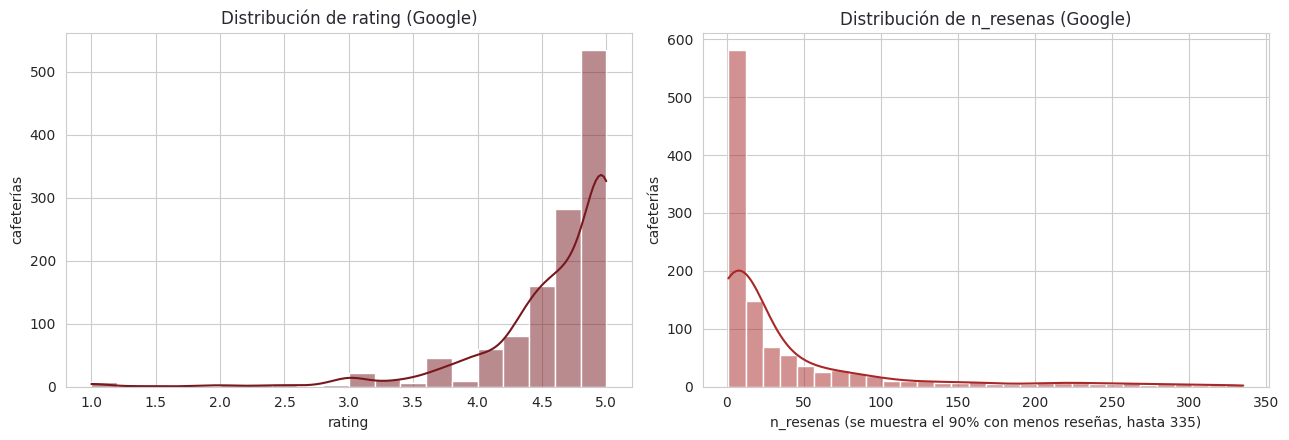

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(places['rating'].dropna(), bins=20, color=color2, kde=True, ax=axes[0])
axes[0].set_title('Distribución de rating (Google)', color=color1)
axes[0].set_xlabel('rating')

# n_resenas es muy sesgada: la vista se recorta al 90% con menos reseñas (no se descarta nada del análisis)
p90_resenas = places['n_resenas'].quantile(0.90)
sns.histplot(places.loc[places['n_resenas'] <= p90_resenas, 'n_resenas'], bins=30, color=color3, kde=True, ax=axes[1])
axes[1].set_title('Distribución de n_resenas (Google)', color=color1)
axes[1].set_xlabel(f'n_resenas (se muestra el 90% con menos reseñas, hasta {int(p90_resenas)})')
for ax in axes:
    ax.set_ylabel('cafeterías')
plt.tight_layout()
plt.show()

### Asignación de AGEB urbana

Cafeterías fuera de toda AGEB urbana (cerca del borde, dentro del margen de la malla): 16


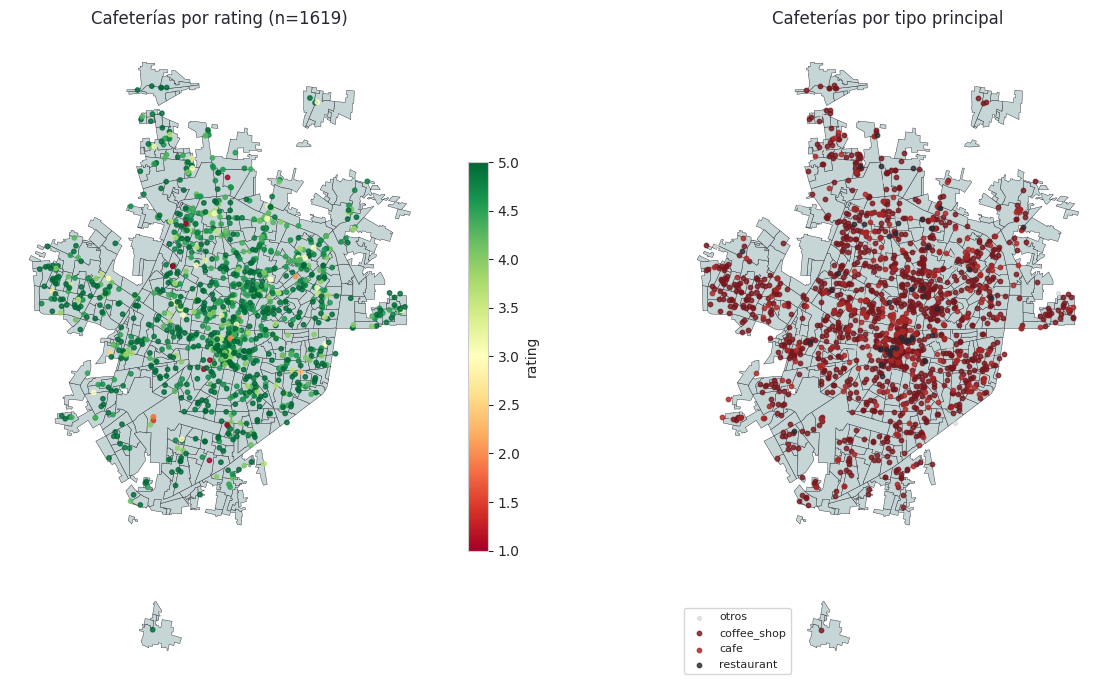

In [16]:
places_ageb = gpd.sjoin(
    gpd.GeoDataFrame(places, geometry=gpd.points_from_xy(places['lon_google'], places['lat_google']),
                     crs='EPSG:4326').to_crs(CRS_M),
    agebs_merida, predicate='within', how='left',
).drop(columns='index_right')

dup = places_ageb['place_id'].duplicated().sum()   # punto sobre el borde de dos AGEB
if dup:
    places_ageb = places_ageb.drop_duplicates(subset='place_id', keep='first')
print(f'Cafeterías fuera de toda AGEB urbana (cerca del borde, dentro del margen de la malla): '
      f'{places_ageb["cvegeo"].isna().sum()}')

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
agebs_merida.plot(ax=axes[0], color=color4, edgecolor=color1, linewidth=0.3)
places_ageb.plot(ax=axes[0], column='rating', cmap='RdYlGn', markersize=10, alpha=0.8,
                 legend=True, legend_kwds={'label': 'rating', 'shrink': 0.6})
axes[0].set_title(f'Cafeterías por rating (n={len(places_ageb)})', color=color1)

top_tipos = places_ageb['primary_type'].value_counts().head(3).index.tolist()
agebs_merida.plot(ax=axes[1], color=color4, edgecolor=color1, linewidth=0.3)
places_ageb[~places_ageb['primary_type'].isin(top_tipos)].plot(ax=axes[1], color='lightgrey', markersize=8,
                                                                alpha=0.6, label='otros')
for tipo, c in zip(top_tipos, [color2, color3, color1]):
    places_ageb[places_ageb['primary_type'] == tipo].plot(ax=axes[1], color=c, markersize=10, alpha=0.8, label=tipo)
axes[1].set_title('Cafeterías por tipo principal', color=color1)
axes[1].legend(loc='lower left', fontsize=8, frameon=True)
for ax in axes:
    ax.set_axis_off()
    ax.set_aspect('equal')
plt.tight_layout()
plt.show()

places_ageb = pd.DataFrame(places_ageb.drop(columns='geometry'))

### Mapas por AGEB

El rating promedio solo se muestra en AGEB con al menos 3 cafeterías; las demás quedan en gris.

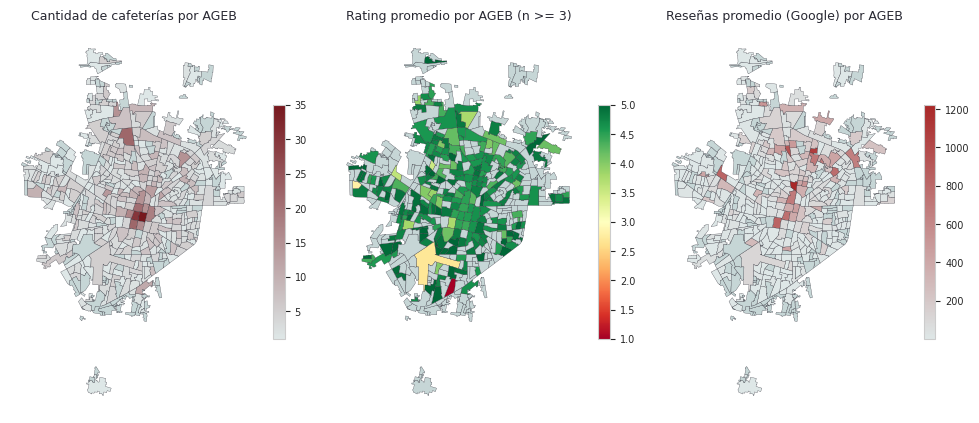

AGEB urbanas con al menos una cafetería: 403 de 541
Las 10 AGEB con más cafeterías concentran 13.2% de las cafeterías ubicadas en una AGEB


In [17]:
MIN_CAFETERIAS_PROMEDIO = 3

resumen_ageb = (places_ageb.dropna(subset=['cvegeo']).groupby('cvegeo')
                .agg(n_cafeterias=('place_id', 'size'), rating_promedio=('rating', 'mean'),
                     n_resenas_promedio=('n_resenas', 'mean'))
                .reset_index())
resumen_ageb.loc[resumen_ageb['n_cafeterias'] < MIN_CAFETERIAS_PROMEDIO, 'rating_promedio'] = np.nan
agebs_resumen = agebs_merida.merge(resumen_ageb, on='cvegeo', how='left')

paneles = [
    ('n_cafeterias', 'Cantidad de cafeterías por AGEB', LinearSegmentedColormap.from_list('c', [color5, color2])),
    ('rating_promedio', f'Rating promedio por AGEB (n >= {MIN_CAFETERIAS_PROMEDIO})', 'RdYlGn'),
    ('n_resenas_promedio', 'Reseñas promedio (Google) por AGEB', LinearSegmentedColormap.from_list('r', [color5, color3])),
]
fig, axes = plt.subplots(1, 3, figsize=(10, 4.2))
for ax, (col, titulo, cmap) in zip(axes, paneles):
    agebs_resumen.plot(ax=ax, column=col, cmap=cmap, edgecolor=color1, linewidth=0.2,
                       legend=True, legend_kwds={'shrink': 0.6},
                       missing_kwds={'color': color4, 'edgecolor': color1, 'linewidth': 0.2})
    fig.axes[-1].tick_params(labelsize=7)
    ax.set_axis_off()
    ax.set_aspect('equal')
plt.tight_layout()
tope = max(ax.get_position().y1 for ax in axes)   # títulos a la misma altura aunque los mapas difieran
for ax, (_, titulo, _) in zip(axes, paneles):
    caja = ax.get_position()
    fig.text((caja.x0 + caja.x1) / 2, tope + 0.02, titulo, ha='center', va='bottom', color=color1, fontsize=9)
plt.show()

top10_ageb = resumen_ageb.sort_values('n_cafeterias', ascending=False).head(10)
print(f'AGEB urbanas con al menos una cafetería: {len(resumen_ageb)} de {len(agebs_merida)}')
print(f'Las 10 AGEB con más cafeterías concentran {top10_ageb["n_cafeterias"].sum() / resumen_ageb["n_cafeterias"].sum():.1%} '
      f'de las cafeterías ubicadas en una AGEB')

### Popularidad, calificación y precio

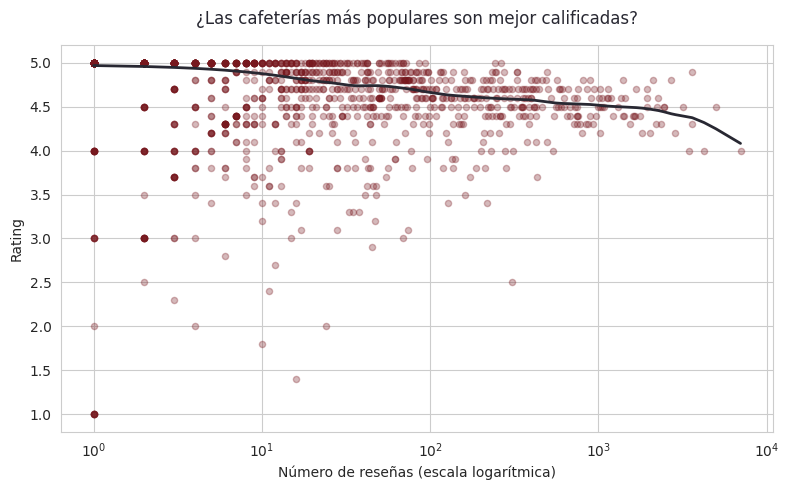

Correlación de Spearman entre rating y número de reseñas: -0.41

Rating mediano por cuartil de popularidad:
popularidad_cuartil
Pocas (Q1)        5.0
Moderadas (Q2)    4.9
Bastantes (Q3)    4.7
Muchas (Q4)       4.6
Name: rating, dtype: float64


In [18]:
etiquetas_popularidad = ['Pocas (Q1)', 'Moderadas (Q2)', 'Bastantes (Q3)', 'Muchas (Q4)']
places['popularidad_cuartil'] = pd.qcut(places['n_resenas'], q=4, labels=etiquetas_popularidad, duplicates='drop')

plt.figure(figsize=(8, 5))
sns.regplot(data=places, x='n_resenas', y='rating', lowess=True,
            scatter_kws={'alpha': 0.3, 'color': color2, 's': 20}, line_kws={'color': color1, 'linewidth': 2})
plt.xscale('log')
plt.title('¿Las cafeterías más populares son mejor calificadas?', color=color1, pad=15)
plt.xlabel('Número de reseñas (escala logarítmica)')
plt.ylabel('Rating')
plt.tight_layout()
plt.show()

print(f"Correlación de Spearman entre rating y número de reseñas: "
      f"{places[['rating', 'n_resenas']].corr(method='spearman').iloc[0, 1]:.2f}")
print('\nRating mediano por cuartil de popularidad:')
print(places.groupby('popularidad_cuartil', observed=True)['rating'].median())

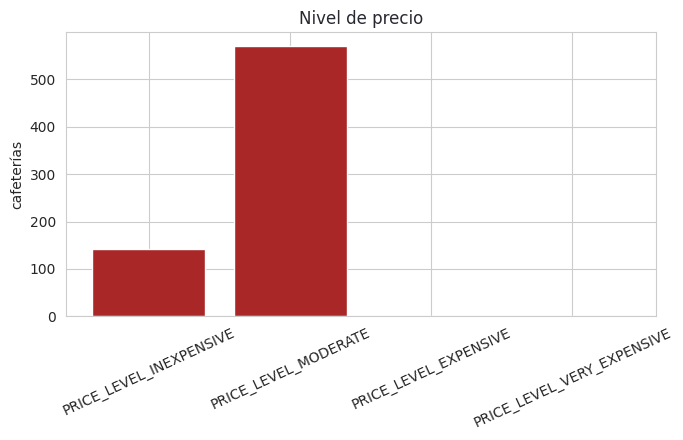

Top 10 AGEB por cantidad de cafeterías:


,cvegeo,n_cafeterias,rating_promedio,n_resenas_promedio
24,3105000010455,35,4.550000,397.200000
23,3105000010440,30,4.553571,757.214286
27,3105000010506,22,4.487500,83.062500
237,3105000014566,22,4.194737,195.315789
14,3105000010328,21,4.453333,373.266667
15,3105000010332,18,4.650000,236.571429
22,3105000010436,17,4.493333,56.866667
28,3105000010510,16,4.415385,18.461538
298,3105000015583,15,4.269231,430.076923
258,3105000014903,15,4.369231,82.230769



Top 10 AGEB por rating promedio (con al menos 3 cafeterías):


,cvegeo,n_cafeterias,rating_promedio,n_resenas_promedio
20,3105000010417,5,5.0,4.750000
39,3105000010667,3,5.0,8.333333
42,3105000010718,5,5.0,3.000000
78,3105000011913,3,5.0,1.000000
49,3105000010826,4,5.0,3.500000
105,3105000012466,3,5.0,3.000000
131,3105000012786,3,5.0,1.000000
145,3105000012979,3,5.0,10.000000
86,3105000012269,3,5.0,7.000000
75,3105000011824,4,5.0,5.000000


In [19]:
orden_precio = ['PRICE_LEVEL_INEXPENSIVE', 'PRICE_LEVEL_MODERATE', 'PRICE_LEVEL_EXPENSIVE', 'PRICE_LEVEL_VERY_EXPENSIVE']
conteo_precio = places['price_level'].value_counts().reindex(orden_precio).dropna()

plt.figure(figsize=(7, 4.5))
plt.bar(conteo_precio.index, conteo_precio.values, color=color3)
plt.title('Nivel de precio', color=color1)
plt.xticks(rotation=25)
plt.ylabel('cafeterías')
plt.tight_layout()
plt.show()

print('Top 10 AGEB por cantidad de cafeterías:')
display(top10_ageb[['cvegeo', 'n_cafeterias', 'rating_promedio', 'n_resenas_promedio']])
print(f'\nTop 10 AGEB por rating promedio (con al menos {MIN_CAFETERIAS_PROMEDIO} cafeterías):')
display(resumen_ageb.dropna(subset=['rating_promedio']).sort_values('rating_promedio', ascending=False).head(10)
        [['cvegeo', 'n_cafeterias', 'rating_promedio', 'n_resenas_promedio']])

## 4. Análisis exploratorio de las reseñas y sentimiento

Hasta 25 reseñas por lugar, extraídas de Google Maps con Selenium (notebook aparte). La copia de datos no incluye
el nombre de las personas autoras.

In [20]:
reviews = pd.read_csv(DATOS / 'reviews_scraped.csv', dtype={'place_id': str})
reviews['review_id'] = reviews.index   # identificador estable: posición en el archivo
reviews['scraped_at'] = pd.to_datetime(reviews['scraped_at'])

print(f'Reseñas: {len(reviews)} | cafeterías con al menos una: {reviews["place_id"].nunique()} de {len(places)}')
print('\nNulos por columna:')
print(reviews.isna().sum())
print('\nCalificación que puso la persona en su reseña:')
print(reviews['rating'].value_counts().sort_index())
print(f'Reseñas de cinco estrellas: {reviews["rating"].eq(5).mean():.1%}')
print('\nReseñas por cafetería:')
print(reviews.groupby('place_id').size().describe().round(1))

Reseñas: 17422 | cafeterías con al menos una: 1223 de 1619

Nulos por columna:
place_id            0
place_name          0
rating              0
relative_date       0
review_text      1737
scraped_at          0
review_id           0
dtype: int64

Calificación que puso la persona en su reseña:
rating
1.0     1284
2.0      441
3.0      724
4.0     1529
5.0    13444
Name: count, dtype: int64
Reseñas de cinco estrellas: 77.2%

Reseñas por cafetería:
count    1223.0
mean       14.2
std        10.1
min         1.0
25%         3.0
50%        15.0
75%        25.0
max        25.0
dtype: float64


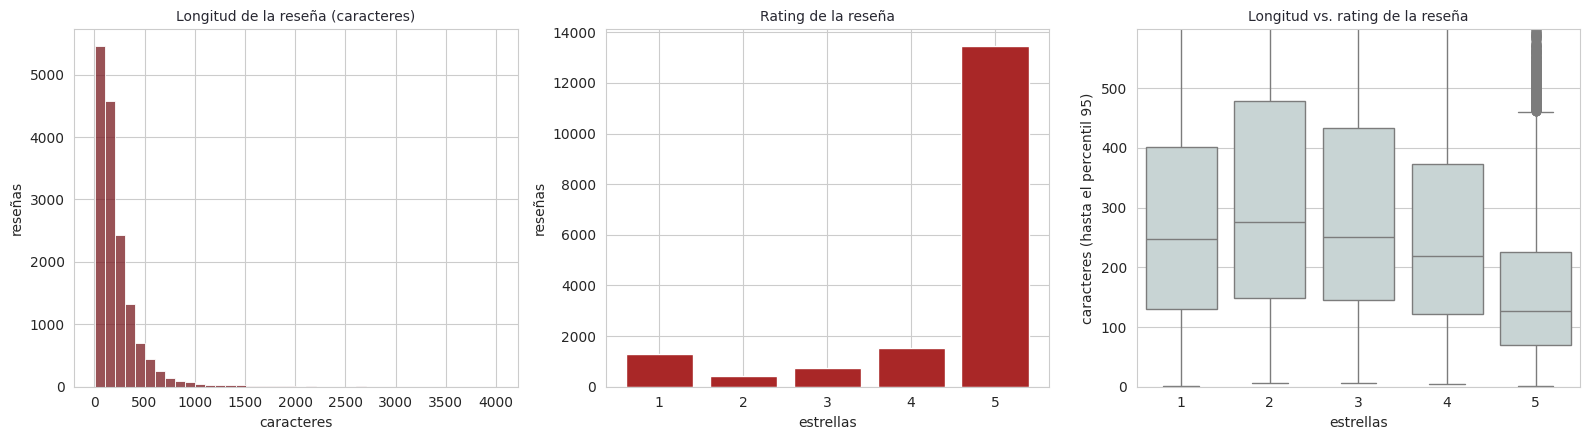

Reseñas sin texto (solo estrellas): 1737 de 17422


In [21]:
reviews['longitud_texto'] = reviews['review_text'].str.len()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(reviews['longitud_texto'].dropna(), bins=40, color=color2, ax=axes[0])
axes[0].set_title('Longitud de la reseña (caracteres)', color=color1, fontsize=10)
axes[0].set_xlabel('caracteres')
conteo_rating = reviews['rating'].value_counts().sort_index()
axes[1].bar(conteo_rating.index, conteo_rating.values, color=color3)
axes[1].set_title('Rating de la reseña', color=color1, fontsize=10)
axes[1].set_xlabel('estrellas')
sns.boxplot(data=reviews, x='rating', y='longitud_texto', color=color4, ax=axes[2])
axes[2].set_title('Longitud vs. rating de la reseña', color=color1, fontsize=10)
axes[2].set_ylim(0, reviews['longitud_texto'].quantile(0.95))
axes[2].set_xticks(range(5))
axes[2].set_xticklabels([1, 2, 3, 4, 5])
axes[2].set_xlabel('estrellas')
axes[2].set_ylabel('caracteres (hasta el percentil 95)')
axes[0].set_ylabel('reseñas')
axes[1].set_ylabel('reseñas')
plt.tight_layout()
plt.show()

print(f'Reseñas sin texto (solo estrellas): {reviews["review_text"].isna().sum()} de {len(reviews)}')

### Palabras y pares de palabras más frecuentes

Sirven para identificar candidatos a características del panel de la Función 2.

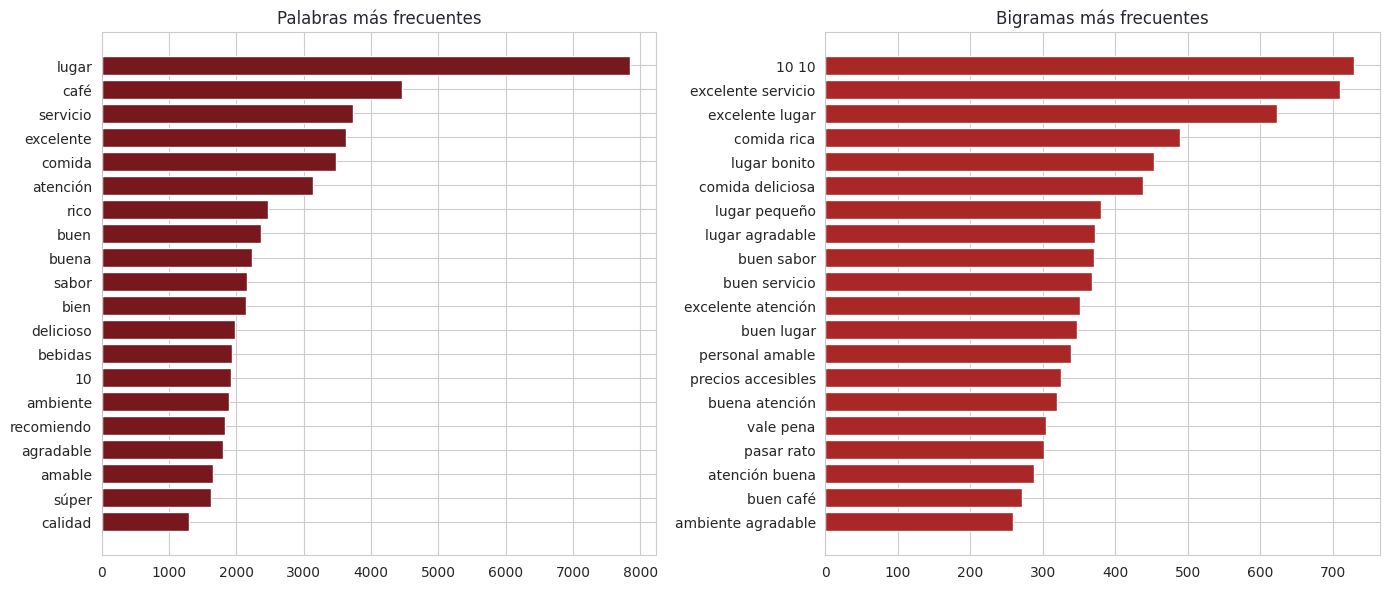

In [22]:
STOPWORDS_ES = {
    'el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'de', 'del', 'al', 'a', 'ante', 'bajo',
    'con', 'contra', 'desde', 'en', 'entre', 'hacia', 'hasta', 'para', 'por', 'según', 'sin', 'sobre',
    'tras', 'y', 'o', 'u', 'e', 'ni', 'que', 'como', 'cuando', 'donde', 'porque', 'pero', 'aunque',
    'si', 'no', 'se', 'su', 'sus', 'mi', 'mis', 'tu', 'tus', 'nos', 'le', 'les', 'lo', 'me', 'te',
    'esta', 'este', 'estos', 'estas', 'ese', 'esa', 'esos', 'esas', 'eso', 'esto', 'muy', 'más',
    'menos', 'tan', 'tanto', 'también', 'solo', 'sólo', 'ya', 'aún', 'todavía', 'así',
    'es', 'son', 'fue', 'fueron', 'ser', 'estar', 'está', 'están', 'estaba', 'estuvo', 'soy', 'eres',
    'somos', 'sois', 'he', 'ha', 'han', 'había', 'habían', 'tiene', 'tienen', 'tenía', 'tuvo', 'hay',
    'yo', 'tú', 'él', 'ella', 'nosotros', 'ustedes', 'ellos', 'ellas', 'usted', 'nuestro', 'nuestra',
    'nuestros', 'nuestras', 'mucho', 'mucha', 'muchos', 'muchas', 'poco', 'poca', 'pocos', 'pocas',
    'todo', 'toda', 'todos', 'todas', 'otro', 'otra', 'otros', 'otras', 'mismo', 'misma', 'cada',
    'algo', 'alguien', 'algún', 'alguna', 'algunos', 'algunas', 'nada', 'nadie', 'ningún', 'ninguna',
    'fui', 'fuimos', 'vamos', 'voy', 'cual', 'cuales', 'quien', 'quienes', 'cuyo', 'cuya', 'qué',
    'cómo', 'cuándo', 'dónde',
}


def top_ngramas(textos, ngram_range, top_n=20, min_df=5):
    """Tabla de los n-gramas más frecuentes (sin palabras vacías) con su frecuencia total."""
    vectorizador = CountVectorizer(stop_words=list(STOPWORDS_ES), ngram_range=ngram_range, min_df=min_df)
    matriz = vectorizador.fit_transform(textos)
    frecuencias = np.asarray(matriz.sum(axis=0)).ravel()
    tabla = pd.DataFrame({'ngrama': vectorizador.get_feature_names_out(), 'frecuencia': frecuencias})
    return tabla.sort_values('frecuencia', ascending=False).head(top_n).reset_index(drop=True)


textos_validos = reviews['review_text'].dropna()
top_unigramas = top_ngramas(textos_validos, (1, 1))
top_bigramas = top_ngramas(textos_validos, (2, 2))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(top_unigramas['ngrama'][::-1], top_unigramas['frecuencia'][::-1], color=color2)
axes[0].set_title('Palabras más frecuentes', color=color1)
axes[1].barh(top_bigramas['ngrama'][::-1], top_bigramas['frecuencia'][::-1], color=color3)
axes[1].set_title('Bigramas más frecuentes', color=color1)
plt.tight_layout()
plt.show()

Reseñas positivas (4 o 5 estrellas): 13400 | negativas (1 o 2): 1636


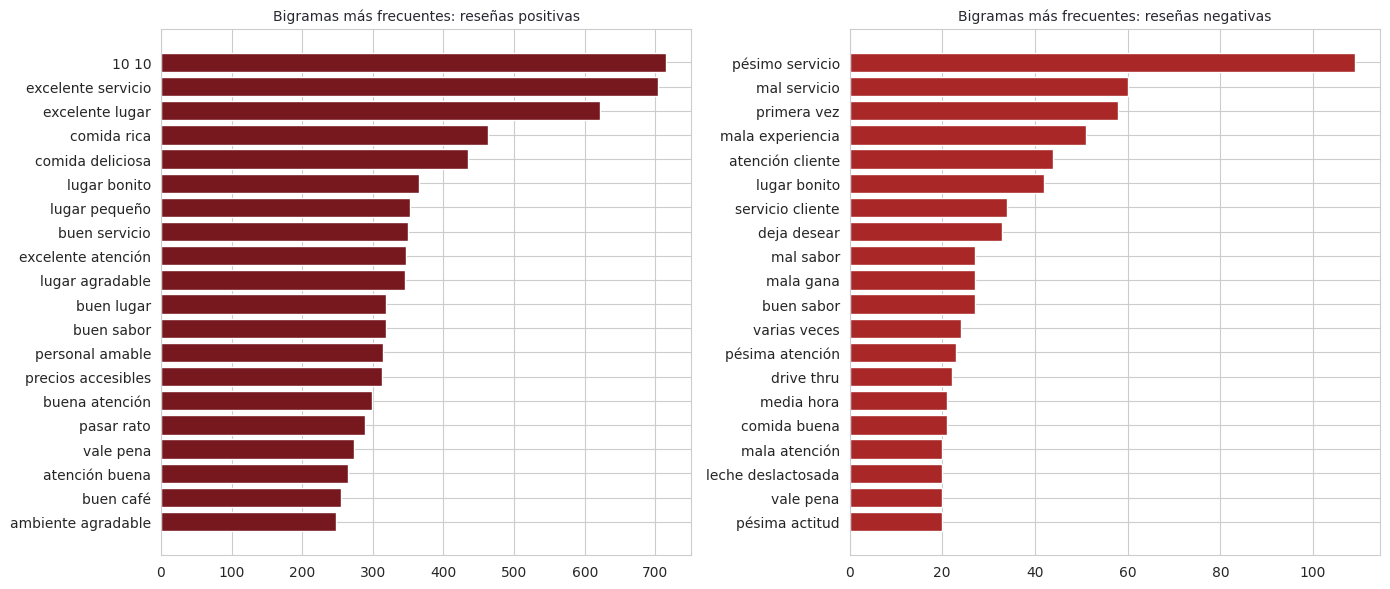

In [23]:
textos_positivos = reviews.loc[reviews['rating'] >= 4, 'review_text'].dropna()
textos_negativos = reviews.loc[reviews['rating'] <= 2, 'review_text'].dropna()
print(f'Reseñas positivas (4 o 5 estrellas): {len(textos_positivos)} | negativas (1 o 2): {len(textos_negativos)}')

top_bigramas_pos = top_ngramas(textos_positivos, (2, 2), min_df=4)
top_bigramas_neg = top_ngramas(textos_negativos, (2, 2), min_df=3)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(top_bigramas_pos['ngrama'][::-1], top_bigramas_pos['frecuencia'][::-1], color=color2)
axes[0].set_title('Bigramas más frecuentes: reseñas positivas', color=color1, fontsize=10)
axes[1].barh(top_bigramas_neg['ngrama'][::-1], top_bigramas_neg['frecuencia'][::-1], color=color3)
axes[1].set_title('Bigramas más frecuentes: reseñas negativas', color=color1, fontsize=10)
plt.tight_layout()
plt.show()

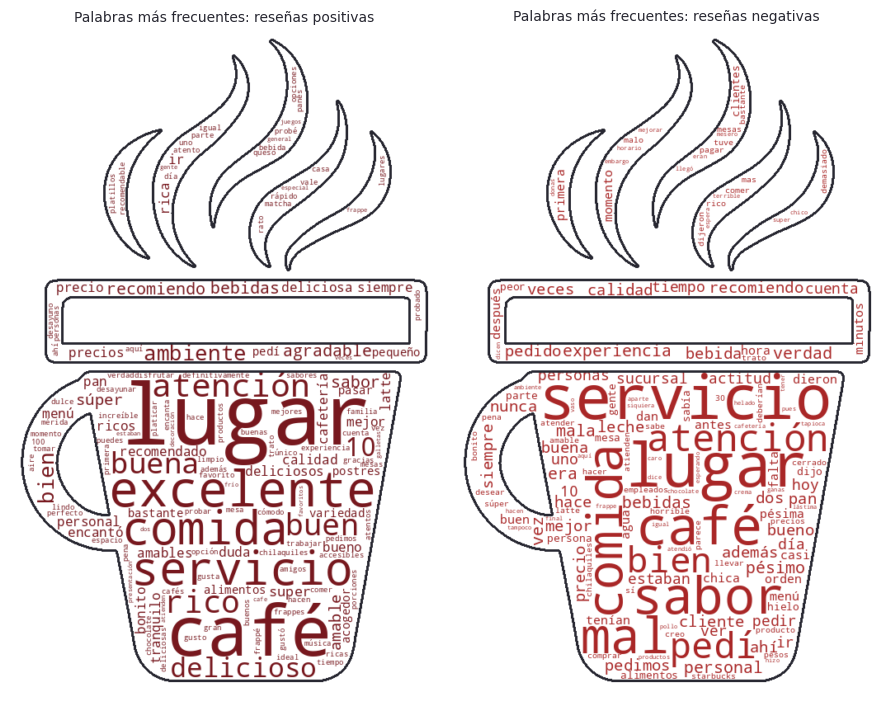

In [24]:
def cargar_mascara_taza(ruta, umbral=200, margen=15):
    """Máscara de la nube de palabras a partir del ícono de taza, recortada a su contorno."""
    arr = np.array(Image.open(ruta).convert('L'))
    mascara = np.where(arr < umbral, 0, 255).astype(np.uint8)
    filas, columnas = np.where(mascara == 0)
    return mascara[max(filas.min() - margen, 0):filas.max() + margen,
                   max(columnas.min() - margen, 0):columnas.max() + margen]


def nube_de_palabras(textos, color, top_n=150, min_df=3):
    """Nube de palabras con forma de taza a partir de las palabras más frecuentes de los textos."""
    tabla = top_ngramas(textos, ngram_range=(1, 1), top_n=top_n, min_df=min_df)
    return WordCloud(mask=mascara_taza, background_color='white', color_func=lambda *a, **k: color,
                     prefer_horizontal=0.9, contour_width=1.5, contour_color=color1, relative_scaling=0.4,
                     min_font_size=6, random_state=42).generate_from_frequencies(dict(zip(tabla['ngrama'],
                                                                                          tabla['frecuencia'])))


mascara_taza = cargar_mascara_taza(DATOS / 'taza_wordcloud.png')
fig, axes = plt.subplots(1, 2, figsize=(9, 7))
for ax, textos, color, titulo in [(axes[0], textos_positivos, color2, 'positivas'),
                                  (axes[1], textos_negativos, color3, 'negativas')]:
    ax.imshow(nube_de_palabras(textos, color), interpolation='bilinear')
    ax.set_title(f'Palabras más frecuentes: reseñas {titulo}', color=color1, fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Sentimiento

Modelo preentrenado `nlptown/bert-base-multilingual-uncased-sentiment` (1 a 5 estrellas), sin ajuste fino, aplicado
solo a las reseñas con texto. Al texto solo se le normalizan los espacios: el modelo espera lenguaje natural. Con
`RECALCULAR = False` se cargan los resultados ya calculados con este mismo modelo.

In [25]:
MODELO_SENTIMIENTO = 'nlptown/bert-base-multilingual-uncased-sentiment'

reviews_con_texto = reviews[reviews['review_text'].notna()].copy()
reviews_con_texto['review_text_limpio'] = reviews_con_texto['review_text'].str.replace(r'\s+', ' ', regex=True).str.strip()
print(f'Reseñas con texto: {len(reviews_con_texto)} | sin texto (no pasan por el modelo): {reviews["review_text"].isna().sum()}')

if RECALCULAR:
    clasificador = pipeline('sentiment-analysis', model=MODELO_SENTIMIENTO, tokenizer=MODELO_SENTIMIENTO,
                            truncation=True, device=0 if torch.cuda.is_available() else -1)
    resultados = clasificador(reviews_con_texto['review_text_limpio'].tolist(), batch_size=32, truncation=True)
    sentimiento = pd.DataFrame({
        'review_id': reviews_con_texto['review_id'].values,
        'sentiment_stars': [int(r['label'][0]) for r in resultados],   # la etiqueta es 'N stars'
        'sentiment_score': [r['score'] for r in resultados],
    })
    sentimiento.to_csv(SALIDAS / 'reviews_sentiment.csv', index=False)
else:
    sentimiento = pd.read_csv(DATOS / 'reviews_sentiment.csv')

print(f'Sentimiento disponible para {len(sentimiento)} reseñas')
sentimiento.head()

Reseñas con texto: 15685 | sin texto (no pasan por el modelo): 1737
Sentimiento disponible para 15685 reseñas


,review_id,sentiment_stars,sentiment_score
0,0,3,0.411549
1,1,5,0.636909
2,2,5,0.887943
3,3,5,0.498613
4,4,5,0.677424


Coincidencia exacta: 76.4% | dentro de ±1 estrella: 95.6%


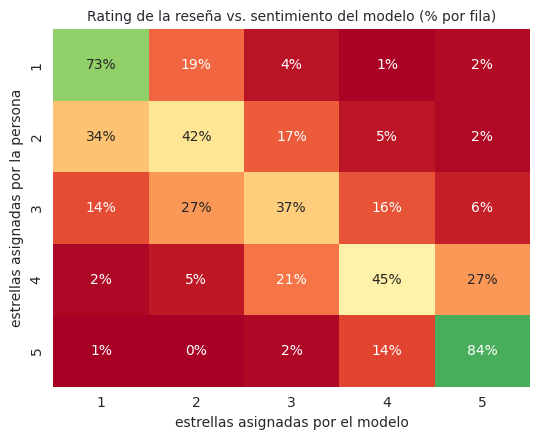

In [26]:
# Validación: estrellas del modelo frente a las que puso la propia persona
reviews_con_texto = reviews_con_texto.merge(sentimiento, on='review_id', how='left')
reviews_con_texto['rating_int'] = reviews_con_texto['rating'].round().astype(int)
matriz_confusion = pd.crosstab(reviews_con_texto['rating_int'], reviews_con_texto['sentiment_stars'])

exacto = (reviews_con_texto['rating_int'] == reviews_con_texto['sentiment_stars']).mean()
en_uno = (reviews_con_texto['rating_int'] - reviews_con_texto['sentiment_stars']).abs().le(1).mean()
print(f'Coincidencia exacta: {exacto:.1%} | dentro de ±1 estrella: {en_uno:.1%}')

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(matriz_confusion.div(matriz_confusion.sum(axis=1), axis=0), annot=True, fmt='.0%',
            cmap='RdYlGn', cbar=False, vmin=0, vmax=1)
plt.xlabel('estrellas asignadas por el modelo')
plt.ylabel('estrellas asignadas por la persona')
plt.title('Rating de la reseña vs. sentimiento del modelo (% por fila)', color=color1, fontsize=10)
plt.tight_layout()
plt.show()

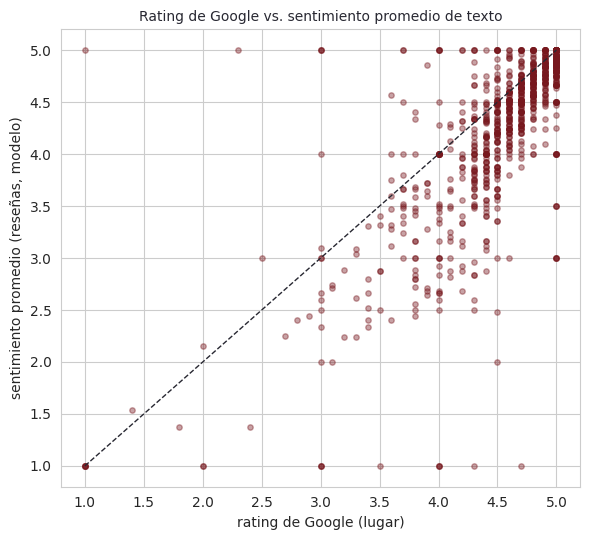

Correlación entre rating y sentimiento promedio: 0.77
Lugares con sentimiento más de una estrella por debajo de su rating: 38 de 771 (con al menos 5 reseñas con texto)

Rating de Google más alto que el sentimiento de sus reseñas:


,nombre_google,rating,sentimiento_promedio,n_resenas_con_texto
273,Starbucks Gran Santa Fé,4.5,2.480000,25
973,2191 Santa Clara Uptown,4.3,2.600000,25
148,Starbucks,4.4,2.880000,25
1099,2023 Santa Clara Galerías,4.2,2.680000,25
162,SA. BE A CAFÉ,4.3,2.833333,6
88,Dunkin' Buenavista,4.3,2.840000,25
1050,Bubbaplop! Plaza Las Américas - Frappés con Tapioca,4.0,2.600000,25
1091,YUCHA,3.8,2.440000,25
884,The Italian Coffee | Aviación,4.3,2.960000,25
382,Bubbaplop! Villas - Frappés con Tapioca,4.2,2.880000,25


Sentimiento de las reseñas más alto que su rating de Google:


,nombre_google,rating,sentimiento_promedio,n_resenas_con_texto
129,Caneroll MID,3.6,4.571429,7
320,Snoopy Frapp Frappes del parque,3.9,4.857143,7
802,Gerona Tavola Rustica,4.3,5.000000,5
178,Eve Food,3.8,4.400000,10
602,Café de la esquina,4.4,5.000000,5
438,Café Orgánico,4.3,4.888889,9
324,Maison Kayser,2.5,3.000000,25
159,The Food Store,4.5,4.916667,12
1104,"CAFETERÍA Y LONCHERÍA "" LA ESTACIÓN """,4.6,5.000000,10
992,HIGHMILLS,3.6,4.000000,9


In [27]:
sentimiento_por_lugar = (reviews_con_texto.groupby('place_id')
                         .agg(sentimiento_promedio=('sentiment_stars', 'mean'),
                              sentimiento_std=('sentiment_stars', 'std'),
                              n_resenas_con_texto=('sentiment_stars', 'size'))
                         .reset_index())

comparacion = sentimiento_por_lugar.merge(places[['place_id', 'nombre_google', 'rating']], on='place_id', how='left')
comparacion['brecha'] = comparacion['sentimiento_promedio'] - comparacion['rating']

plt.figure(figsize=(6, 5.5))
plt.scatter(comparacion['rating'], comparacion['sentimiento_promedio'], alpha=0.4, s=15, color=color2)
plt.plot([1, 5], [1, 5], color=color1, linestyle='--', linewidth=1)
plt.xlabel('rating de Google (lugar)')
plt.ylabel('sentimiento promedio (reseñas, modelo)')
plt.title('Rating de Google vs. sentimiento promedio de texto', color=color1, fontsize=10)
plt.tight_layout()
plt.show()

con_muestra = comparacion[comparacion['n_resenas_con_texto'] >= 5]   # brecha con al menos 5 reseñas con texto
print(f"Correlación entre rating y sentimiento promedio: {comparacion[['rating', 'sentimiento_promedio']].corr().iloc[0, 1]:.2f}")
print(f"Lugares con sentimiento más de una estrella por debajo de su rating: {(con_muestra['brecha'] < -1).sum()} "
      f"de {len(con_muestra)} (con al menos 5 reseñas con texto)")

columnas = ['nombre_google', 'rating', 'sentimiento_promedio', 'n_resenas_con_texto']
print('\nRating de Google más alto que el sentimiento de sus reseñas:')
display(con_muestra.nsmallest(10, 'brecha')[columnas])
print('Sentimiento de las reseñas más alto que su rating de Google:')
display(con_muestra.nlargest(10, 'brecha')[columnas])

## 5. Ingeniería de variables

Se arman las dos tablas que usa el modelo. No se imputa ningún valor: el nulo indica que algo no se pudo calcular
y una cafetería sin reseñas extraídas se registra con cero.

- `apto_recomendador`: al menos 1 reseña con texto; la cafetería puede recomendarse.
- `baja_confianza`: menos de 5 reseñas con texto; se recomienda, pero su puntaje se pondera.

In [28]:
MIN_RESENAS_CONFIABLE = 5

agregados_reviews = (reviews.groupby('place_id')
                     .agg(n_resenas_scrapeadas=('review_id', 'size'), rating_resenas_promedio=('rating', 'mean'))
                     .reset_index())
cafeterias_features = (places_ageb
                       .merge(agregados_reviews, on='place_id', how='left')
                       .merge(sentimiento_por_lugar, on='place_id', how='left'))
for col in ['n_resenas_scrapeadas', 'n_resenas_con_texto']:
    cafeterias_features[col] = cafeterias_features[col].fillna(0).astype(int)

cafeterias_features['apto_recomendador'] = cafeterias_features['n_resenas_con_texto'] >= 1
cafeterias_features['baja_confianza'] = (cafeterias_features['apto_recomendador']
                                         & (cafeterias_features['n_resenas_con_texto'] < MIN_RESENAS_CONFIABLE))
cafeterias_features.to_csv(SALIDAS / 'cafeterias_features.csv', index=False)

reviews_features = (reviews
                    .merge(sentimiento, on='review_id', how='left')
                    .merge(reviews_con_texto[['review_id', 'review_text_limpio']], on='review_id', how='left'))
reviews_features['sin_texto'] = reviews_features['review_text'].isna()
reviews_features.to_csv(SALIDAS / 'reviews_features.csv', index=False)

print(f'cafeterias_features: {cafeterias_features.shape} | apto_recomendador: {cafeterias_features["apto_recomendador"].sum()} '
      f'| de ellas, baja_confianza: {cafeterias_features["baja_confianza"].sum()}')
print(f'reviews_features: {reviews_features.shape} | sin_texto: {reviews_features["sin_texto"].sum()} '
      f'| sentimiento nulo: {reviews_features["sentiment_stars"].isna().sum()}')
print('\nNulos que quedan en columnas clave de cafeterias_features:')
print(cafeterias_features[['cvegeo', 'rating', 'sentimiento_promedio', 'rating_resenas_promedio']].isna().sum())

cafeterias_features: (1619, 23) | apto_recomendador: 1111 | de ellas, baja_confianza: 340
reviews_features: (17422, 12) | sin_texto: 1737 | sentimiento nulo: 1737

Nulos que quedan en columnas clave de cafeterias_features:
cvegeo                      16
rating                     389
sentimiento_promedio       508
rating_resenas_promedio    396
dtype: int64


In [29]:
# Candidatos a características: n-gramas frecuentes con un ejemplo real (la lista final se curó a mano)
def ejemplo_review(ngrama, max_chars=140):
    """Primera reseña que contiene el n-grama, recortada a `max_chars` caracteres."""
    coincide = reviews['review_text'].str.contains(re.escape(ngrama), case=False, na=False, regex=True)
    if not coincide.any():
        return None
    texto = reviews.loc[coincide, 'review_text'].iloc[0]
    return texto if len(texto) <= max_chars else texto[:max_chars] + '…'


candidatos = pd.concat([top_ngramas(textos_validos, (1, 1), top_n=40, min_df=5).assign(tipo='unigrama'),
                        top_ngramas(textos_validos, (2, 2), top_n=40, min_df=4).assign(tipo='bigrama')],
                       ignore_index=True)
candidatos['ejemplo'] = candidatos['ngrama'].apply(ejemplo_review)
candidatos = candidatos.sort_values(['tipo', 'frecuencia'], ascending=[True, False]).reset_index(drop=True)
candidatos.to_csv(SALIDAS / 'tags_candidatos.csv', index=False)
candidatos.head(15)

,ngrama,frecuencia,tipo,ejemplo
0,10 10,729,bigrama,None
1,excelente servicio,710,bigrama,"Los Machetes son extraordinarios, les recomendamos el capuchino maya, las co..."
2,excelente lugar,623,bigrama,"Un excelente lugar para comer o cenar, están abiertos las 24hrs, comida muy ..."
3,comida rica,489,bigrama,Ir a desayunar a la casa de los abuelos es buena opción si vamos con nuestro...
4,lugar bonito,453,bigrama,"Excelente atención de todo el equipo desde la hostess, mesera Rocio, la seño..."
5,comida deliciosa,439,bigrama,"Excelente y amable servicio del mesero Manuel Ojeda, la comida deliciosa y e..."
6,lugar pequeño,381,bigrama,Alma de piedra es un restaurante que hace honor a su fama y recomendación.\n...
7,lugar agradable,372,bigrama,"Muy buena atención, variedad de sabores, lugar agradable para tomar un café ..."
8,buen sabor,371,bigrama,"Excelente experiencia. Alberto nos brindó una atención excepcional, siempre ..."
9,buen servicio,368,bigrama,"Lo usual, muy buen servicio y lugar muy, pero muy agradable para estar solo ..."


## 6. Modelo de recomendación

No se entrena ni se ajusta ningún modelo. Cada reseña con texto se representa con
`paraphrase-multilingual-MiniLM-L12-v2` (vector de 384 dimensiones); el vector de una cafetería es el promedio
normalizado de los de sus reseñas, y se recomienda por similitud del coseno:

- **Función 1** (de una cafetería a las más similares): vecinos más cercanos de la cafetería elegida.
- **Función 2** (de características a cafeterías): las características elegidas se unen en un texto que se
  representa con el mismo modelo.

En ambas el orden lo da `coseno * min(1, n_resenas_con_texto / 5)`, para que las cafeterías con pocas reseñas no
ocupen los primeros lugares.

In [30]:
NOMBRE_MODELO = 'paraphrase-multilingual-MiniLM-L12-v2'
UMBRAL_POSITIVO, UMBRAL_NEUTRO = 4.0, 3.0   # sentimiento de la tarjeta: Positivo, Neutro o Negativo

aptas = cafeterias_features[cafeterias_features['apto_recomendador']].reset_index(drop=True)
resenas_texto = reviews_features[(~reviews_features['sin_texto'])
                                 & reviews_features['place_id'].isin(aptas['place_id'])].reset_index(drop=True)
print(f'Cafeterías candidatas: {len(aptas)} de {len(cafeterias_features)} '
      f'(baja confianza: {aptas["baja_confianza"].sum()}) | reseñas con texto: {len(resenas_texto)}')

dispositivo = 'cuda' if RECALCULAR and torch.cuda.is_available() else 'cpu'
modelo = SentenceTransformer(NOMBRE_MODELO, device=dispositivo)
DIM = (modelo.get_embedding_dimension() if hasattr(modelo, 'get_embedding_dimension')
       else modelo.get_sentence_embedding_dimension())

if RECALCULAR:
    emb_resenas = modelo.encode(resenas_texto['review_text_limpio'].tolist(), batch_size=64,
                                convert_to_numpy=True, show_progress_bar=False).astype(np.float32)
    np.savez(SALIDAS / 'reviews_embeddings.npz', review_id=resenas_texto['review_id'].to_numpy(np.int64),
             embeddings=emb_resenas)
else:
    ck = np.load(DATOS / 'reviews_embeddings.npz')
    posicion = pd.Series(np.arange(len(ck['review_id'])), index=ck['review_id'])
    emb_resenas = ck['embeddings'][posicion.loc[resenas_texto['review_id']].to_numpy()]

print(f'Modelo: {NOMBRE_MODELO} | dimensión: {DIM} | máximo de tokens por texto: {modelo.max_seq_length}')
print(f'Matriz de embeddings de reseñas: {emb_resenas.shape} | valores nulos: {int(np.isnan(emb_resenas).sum())}')

Cafeterías candidatas: 1111 de 1619 (baja confianza: 340) | reseñas con texto: 15685
Modelo: paraphrase-multilingual-MiniLM-L12-v2 | dimensión: 384 | máximo de tokens por texto: 128
Matriz de embeddings de reseñas: (15685, 384) | valores nulos: 0


### Vector por cafetería y centrado (Función 1)

Los *embeddings* de frases tienden a parecerse entre sí, y unas pocas cafeterías pueden aparecer como vecinas de
muchas (*hubness*). Se compara usar los vectores tal cual o centrados (restando el vector medio).

In [31]:
def normalizar(m):
    """Normaliza a norma 1 por filas (o un vector suelto), sin dividir entre cero."""
    m = np.asarray(m, dtype=np.float32)
    n = np.linalg.norm(m, axis=-1, keepdims=True)
    return m / np.where(n == 0, 1.0, n)


place_ids = aptas['place_id'].tolist()
fila = pd.Series(np.arange(len(place_ids)), index=place_ids).loc[resenas_texto['place_id']].to_numpy()

# Promedio de los embeddings normalizados de cada cafetería, normalizado de nuevo
sumas = np.zeros((len(place_ids), DIM), dtype=np.float32)
np.add.at(sumas, fila, normalizar(emb_resenas))
n_texto = np.bincount(fila, minlength=len(place_ids))
vectores_planos = normalizar(sumas / n_texto[:, None])
centro = vectores_planos.mean(axis=0)
vectores_centrados = normalizar(vectores_planos - centro)
confianza = np.minimum(1.0, n_texto / MIN_RESENAS_CONFIABLE)

STOP_MARCA = {'cafe', 'cafeteria', 'la', 'el', 'los', 'las', 'the', 'de', 'restaurante', 'panaderia', 'pasteleria'}


def marca(nombre):
    """Marca aproximada: primera palabra del nombre que no sea genérica."""
    t = unicodedata.normalize('NFKD', str(nombre).lower()).encode('ascii', 'ignore').decode()
    palabras = re.findall(r'[a-z0-9]+', t)
    for p in palabras:
        if p not in STOP_MARCA:
            return p
    return palabras[0] if palabras else ''


marcas = np.array([marca(n) for n in aptas['nombre_google']])
misma_marca = marcas[:, None] == marcas[None, :]
np.fill_diagonal(misma_marca, False)
base_marca = misma_marca.sum() / (len(marcas) * (len(marcas) - 1))


def diagnostico(vectores, ponderar):
    """Indicadores de escala y hubness de los 3 vecinos más cercanos de cada cafetería."""
    sim = vectores @ vectores.T
    fuera_diag = sim[~np.eye(len(sim), dtype=bool)]
    ranking = sim * (confianza[None, :] if ponderar else 1.0)
    np.fill_diagonal(ranking, -np.inf)
    vecinos = np.argsort(-ranking, axis=1)[:, :3]
    apariciones = np.bincount(vecinos.ravel(), minlength=len(sim))
    return {
        'coseno medio entre pares': fuera_diag.mean(),
        'coseno medio del vecino 1': sim[np.arange(len(sim)), vecinos[:, 0]].mean(),
        'apariciones máx. en top-3': apariciones.max(),
        '% que nunca aparece': (apariciones == 0).mean() * 100,
        'asimetría de apariciones': pd.Series(apariciones).skew(),
        '% vecinos de la misma marca': misma_marca[np.arange(len(sim))[:, None], vecinos].mean() * 100,
    }


print(f'Vectores por cafetería: {vectores_planos.shape}')
print(f'Probabilidad de que un par al azar sea de la misma marca: {base_marca * 100:.1f}%')
pd.DataFrame({
    'sin centrar': diagnostico(vectores_planos, False),
    'sin centrar + ponderado': diagnostico(vectores_planos, True),
    'centrado': diagnostico(vectores_centrados, False),
    'centrado + ponderado': diagnostico(vectores_centrados, True),
}).round(3)

Vectores por cafetería: (1111, 384)
Probabilidad de que un par al azar sea de la misma marca: 0.2%


,sin centrar,sin centrar + ponderado,centrado,centrado + ponderado
coseno medio entre pares,0.684,0.684,0.009,0.009
coseno medio del vecino 1,0.900,0.895,0.665,0.646
apariciones máx. en top-3,27.000,39.000,20.000,34.000
% que nunca aparece,31.503,40.684,22.412,38.434
asimetría de apariciones,2.227,2.397,1.661,2.336
% vecinos de la misma marca,4.320,4.320,4.800,4.950


**Decisión.** La Función 1 usa los vectores centrados. Sin centrar, el coseno medio entre cualquier par de
cafeterías es de 0.68 y casi todas parecen muy similares; al centrar baja a cerca de 0, el *hubness* disminuye y
los vecinos de la misma marca se conservan.

In [32]:
emb_lugar = vectores_centrados

### Plantilla de consulta (Función 2)

Sin etiquetas de relevancia, una cafetería se considera relevante para una consulta si al menos 2 de sus reseñas
mencionan el tema (expresión regular). Se mide la precisión en los 5 y 10 primeros resultados (P@5, P@10) frente a
la tasa base, que es lo que acertaría un orden al azar. La plantilla se elige con las mismas consultas con que se
mide, por lo que la mejora es algo optimista.

In [33]:
TEMA_TRANQUILO = r'tranquil'
TEMA_TRABAJAR = r'trabajar|laptop|home office|computadora'
TEMA_WIFI = r'wi-?fi|internet'
TEMA_MASCOTAS = r'pet friendly|mascota|perr(?:o|ito)'
TEMA_TERRAZA = r'terraza|patio|jard[ií]n|aire libre'
TEMA_POSTRES = r'postre|pastel|cheesecake|\bpay\b'
TEMA_DESAYUNO = r'desayun'

# (texto de la consulta, expresión regular del tema)
CONSULTAS = [
    ('ambiente tranquilo', TEMA_TRANQUILO),
    ('para trabajar', TEMA_TRABAJAR),
    ('buen wifi', TEMA_WIFI),
    ('pet friendly', TEMA_MASCOTAS),
    ('postres ricos', TEMA_POSTRES),
    ('aire acondicionado', r'aire acondicionado|clima'),
    ('juegos de mesa', r'juegos? de mesa|juegos mesa'),
    ('terraza', TEMA_TERRAZA),
    ('desayunos', TEMA_DESAYUNO),
    ('lugar acogedor', r'acogedor'),
    ('espacio amplio', r'amplio|espacioso'),
    ('buena música', r'm[uú]sica'),
    ('ambiente tranquilo para trabajar', f'{TEMA_TRANQUILO}|{TEMA_TRABAJAR}'),
    ('ambiente tranquilo buen wifi para trabajar', f'{TEMA_TRANQUILO}|{TEMA_TRABAJAR}|{TEMA_WIFI}'),
    ('pet friendly terraza', f'{TEMA_MASCOTAS}|{TEMA_TERRAZA}'),
    ('postres ricos desayunos', f'{TEMA_POSTRES}|{TEMA_DESAYUNO}'),
]
textos = resenas_texto['review_text_limpio']


def menciones_por_lugar(patron):
    """Número de reseñas de cada cafetería candidata que coinciden con la expresión regular."""
    coincide = textos.str.contains(patron, case=False, regex=True, na=False).to_numpy()
    m = np.zeros(len(place_ids), dtype=int)
    np.add.at(m, fila[coincide], 1)
    return m


relevantes = [menciones_por_lugar(p) >= 2 for _, p in CONSULTAS]
tasa_base = np.array([r.mean() for r in relevantes])


def evaluar(puntajes):
    """Métricas de una lista de puntajes (uno por consulta, un valor por cafetería)."""
    p5 = np.array([r[np.argsort(-s)[:5]].mean() for r, s in zip(relevantes, puntajes)])
    p10 = np.array([r[np.argsort(-s)[:10]].mean() for r, s in zip(relevantes, puntajes)])
    return {'P@5': p5.mean(), 'P@10': p10.mean(), 'lift P@10': (p10 / tasa_base).mean(),
            'consultas con P@10 = 0': int((p10 == 0).sum())}


PLANTILLAS = ['{texto}', 'Es un lugar con {texto}', 'Un lugar con {texto}', 'Cafetería con {texto}',
              'Lugar: {texto}', 'Este café tiene {texto}']
filas = []
for plantilla in PLANTILLAS:
    q = normalizar(modelo.encode([plantilla.format(texto=c) for c, _ in CONSULTAS], convert_to_numpy=True))
    sin_centrar = [(vectores_planos @ qi) * confianza for qi in q]
    centrado = [(vectores_centrados @ normalizar(qi - centro)) * confianza for qi in q]
    filas.append({'plantilla': plantilla, 'vectores': 'sin centrar', **evaluar(sin_centrar)})
    filas.append({'plantilla': plantilla, 'vectores': 'centrados', **evaluar(centrado)})

print(f'{len(CONSULTAS)} consultas | tasa base media: {tasa_base.mean():.3f}')
pd.DataFrame(filas).round(2)

16 consultas | tasa base media: 0.138


,plantilla,vectores,P@5,P@10,lift P@10,consultas con P@10 = 0
0,{texto},sin centrar,0.38,0.38,2.72,5
1,{texto},centrados,0.35,0.31,2.10,6
2,Es un lugar con {texto},sin centrar,0.62,0.61,5.63,1
3,Es un lugar con {texto},centrados,0.54,0.52,4.66,1
4,Un lugar con {texto},sin centrar,0.60,0.53,4.63,2
5,Un lugar con {texto},centrados,0.50,0.48,4.12,2
6,Cafetería con {texto},sin centrar,0.44,0.42,4.33,0
7,Cafetería con {texto},centrados,0.32,0.41,3.95,1
8,Lugar: {texto},sin centrar,0.51,0.49,4.04,3
9,Lugar: {texto},centrados,0.44,0.44,3.69,3


**Decisión.** La Función 2 usa los vectores sin centrar y la plantilla "Es un lugar con {texto}". Centrar no ayuda
en esta función, por lo que el modelo guarda los dos conjuntos de vectores. El resultado es sensible a la
redacción: "Este café tiene {texto}" queda por debajo del azar.

In [34]:
emb_texto = vectores_planos
PLANTILLA_CONSULTA = 'Es un lugar con {texto}'

### Vocabulario de características y atributos de las tarjetas

Las 20 características del panel de la aplicación. La expresión regular de cada una solo sirve para verificar
evidencia en las reseñas; la recomendación se hace con *embeddings*. Una característica se muestra como atributo
de una cafetería solo si al menos 2 de sus reseñas la mencionan.

In [35]:
# etiqueta que ve la persona usuaria -> expresión regular de evidencia
TAGS = {
    'ambiente tranquilo': TEMA_TRANQUILO,
    'para trabajar': TEMA_TRABAJAR,
    'buen wifi': TEMA_WIFI,
    'pet friendly': TEMA_MASCOTAS,
    'postres ricos': TEMA_POSTRES,
    'aire acondicionado': r'aire acondicionado|clima',
    'juegos de mesa': r'juegos? de mesa|juegos mesa',
    'lugar acogedor': r'acogedor',
    'terraza': TEMA_TERRAZA,
    'desayunos': TEMA_DESAYUNO,
    'precios accesibles': r'precios? accesibles?|econ[oó]mic|barato',
    'servicio amable': r'amable|atento',
    'buena música': r'm[uú]sica',
    'espacio amplio': r'amplio|espacioso',
    'estacionamiento': r'estacionamiento|parking',
    'helados': r'helado|nieve|paleta',
    'panadería': r'panader|croissant|pan dulce|\bpanes?\b|baguette|bolillo',
    'decoración bonita': r'decoraci[oó]n|decorad|lindo lugar|bonito lugar|hermoso lugar',
    'servicio rápido': r'r[aá]pid',
    'para reunirse con amigos': r'amigos|reuni',
}
MIN_CAFETERIAS_TAG = 15      # una característica con menos evidencia no se ofrece en el panel
MIN_MENCIONES_ATRIBUTO = 2
N_ATRIBUTOS = 3
Z_MINIMO = 0.5

menciones = np.column_stack([menciones_por_lugar(p) for p in TAGS.values()])   # (cafeterías, características)
col_tag = {t: j for j, t in enumerate(TAGS)}
tags = [t for t in TAGS if (menciones[:, col_tag[t]] >= MIN_MENCIONES_ATRIBUTO).sum() >= MIN_CAFETERIAS_TAG]

# Atributos: entre las características con evidencia, las 3 de mayor afinidad relativa (puntaje z del embedding)
emb_tags = normalizar(modelo.encode([PLANTILLA_CONSULTA.format(texto=t) for t in tags], convert_to_numpy=True))
sim_tags = emb_texto @ emb_tags.T
z = (sim_tags - sim_tags.mean(axis=0)) / sim_tags.std(axis=0)
con_evidencia = np.column_stack([menciones[:, col_tag[t]] >= MIN_MENCIONES_ATRIBUTO for t in tags])
z_valido = np.where(con_evidencia, z, -np.inf)
atributos = []
for i in range(len(place_ids)):
    orden = np.argsort(-z_valido[i])[:N_ATRIBUTOS]
    atributos.append([tags[j] for j in orden if z_valido[i, j] >= Z_MINIMO])

print(f'Características que se ofrecen: {len(tags)} de {len(TAGS)}')
print(f'Cafeterías con al menos 1 atributo: {sum(bool(a) for a in atributos)} de {len(place_ids)}')
pd.DataFrame({
    'característica': list(TAGS),
    'reseñas que la mencionan': menciones.sum(axis=0),
    'cafeterías con >= 2 menciones': (menciones >= 2).sum(axis=0),
    'veces asignada como atributo': [sum(t in a for a in atributos) for t in TAGS],
}).sort_values('cafeterías con >= 2 menciones', ascending=False).reset_index(drop=True)

Características que se ofrecen: 20 de 20
Cafeterías con al menos 1 atributo: 574 de 1111


,característica,reseñas que la mencionan,cafeterías con >= 2 menciones,veces asignada como atributo
0,servicio amable,3000,574,180
1,ambiente tranquilo,866,238,121
2,postres ricos,1123,222,122
3,desayunos,1079,215,170
4,panadería,912,195,126
5,lugar acogedor,728,186,64
6,servicio rápido,717,177,46
7,decoración bonita,586,142,64
8,para trabajar,485,109,46
9,aire acondicionado,456,104,48


### Clase `Recomendador`

Reúne los dos métodos sobre un artefacto que solo contiene datos (matrices, listas y textos). Es la misma lógica que
usa el servicio de la aplicación.

In [36]:
class PlaceNotFoundError(LookupError):
    """El place_id no está entre las cafeterías recomendables."""


class Recomendador:
    """Recomendador de cafeterías por similitud del coseno sobre embeddings de reseñas.

    La Función 1 (`recomendar_por_lugar`) usa los vectores centrados y la Función 2
    (`recomendar_por_texto`) los vectores sin centrar con la plantilla de consulta. En
    ambas, el orden lo da coseno * confianza, con confianza = min(1, n_texto / 5).
    """

    def __init__(self, artefacto, modelo_texto=None):
        self.nombre_modelo = artefacto['modelo_embeddings']
        self.dim = int(artefacto['dim'])
        self.embeddings = np.asarray(artefacto['embeddings'], dtype=np.float32)
        self.embeddings_lugar = np.asarray(artefacto['embeddings_lugar'], dtype=np.float32)
        self.plantilla_consulta = artefacto['plantilla_consulta']
        self.place_ids = list(artefacto['place_ids'])
        self.cafeterias = list(artefacto['cafeterias'])
        self.tags = list(artefacto.get('tags', []))
        n_texto = np.array([c['n_resenas_texto'] for c in self.cafeterias], dtype=np.float32)
        self.confianza = np.minimum(1.0, n_texto / artefacto['min_resenas_confiable'])
        self._indice = {pid: i for i, pid in enumerate(self.place_ids)}
        self._modelo_texto = modelo_texto
        if self.embeddings.shape != (len(self.place_ids), self.dim) or self.embeddings_lugar.shape != self.embeddings.shape:
            raise ValueError('Las matrices de embeddings no coinciden con place_ids y dim.')

    @classmethod
    def cargar(cls, ruta, modelo_texto=None):
        """Carga el artefacto `.joblib` (joblib usa pickle: solo abrir archivos propios)."""
        return cls(joblib.load(ruta), modelo_texto)

    def vector_de_texto(self, texto):
        """Representa un texto con el mismo modelo que las reseñas, dentro de la plantilla de consulta."""
        texto = (texto or '').strip()
        if not texto:
            raise ValueError('El texto de la consulta no puede estar vacío.')
        if self._modelo_texto is None:
            self._modelo_texto = SentenceTransformer(self.nombre_modelo, device='cpu')
        frase = self.plantilla_consulta.format(texto=texto)
        return normalizar(self._modelo_texto.encode([frase], convert_to_numpy=True)[0])

    def cosenos_por_texto(self, texto):
        """Coseno sin ponderar entre el texto y todas las cafeterías, en el orden de `place_ids`."""
        return self.embeddings @ self.vector_de_texto(texto)

    def _ranking(self, cosenos, top_k, excluir):
        """Ordena por coseno ponderado, omite los índices de `excluir` y arma los resultados."""
        if top_k < 1:
            raise ValueError('top_k debe ser al menos 1.')
        ponderado = cosenos * self.confianza
        for i in excluir:
            ponderado[i] = -np.inf
        orden = np.argsort(-ponderado)[:min(top_k, len(self.place_ids) - len(excluir))]
        return [{**self.cafeterias[i],
                 'similitud_coseno': round(float(cosenos[i]), 4),
                 'score_similitud': round(float(cosenos[i] * self.confianza[i]), 4)} for i in orden]

    def recomendar_por_lugar(self, place_id, top_k=3, exclude_id=None):
        """Función 1: cafeterías más parecidas a una cafetería dada (sin incluirla)."""
        if place_id not in self._indice:
            raise PlaceNotFoundError(place_id)
        i = self._indice[place_id]
        excluir = {i} | ({self._indice[exclude_id]} if exclude_id in self._indice else set())
        return self._ranking(self.embeddings_lugar @ self.embeddings_lugar[i], top_k, excluir)

    def recomendar_por_texto(self, texto, top_k=10, exclude_id=None):
        """Función 2: cafeterías cuyas reseñas mejor representan un texto (características unidas por espacios)."""
        excluir = {self._indice[exclude_id]} if exclude_id in self._indice else set()
        return self._ranking(self.cosenos_por_texto(texto), top_k, excluir)

    def recommend(self, query, top_k, mode, exclude_id=None):
        """Punto de entrada único: mode='place' (Función 1, query = place_id) o 'text' (Función 2)."""
        if mode == 'place':
            return self.recomendar_por_lugar(query, top_k, exclude_id)
        if mode == 'text':
            return self.recomendar_por_texto(query, top_k, exclude_id)
        raise ValueError(f"mode debe ser 'place' o 'text', no {mode!r}")

    def detalle(self, place_id):
        """Datos de una cafetería (los que muestra su tarjeta)."""
        if place_id not in self._indice:
            raise PlaceNotFoundError(place_id)
        return dict(self.cafeterias[self._indice[place_id]])

In [37]:
def limpio(v):
    """Convierte tipos de numpy y pandas a tipos simples de Python (NaN a None)."""
    if v is None or (not isinstance(v, (str, bool)) and pd.isna(v)):
        return None
    if isinstance(v, np.integer):
        return int(v)
    if isinstance(v, np.floating):
        return float(v)
    if isinstance(v, np.bool_):
        return bool(v)
    return v


def categoria_sentimiento(x):
    """Etiqueta de la tarjeta según el sentimiento promedio (None si no hay)."""
    if x is None:
        return None
    return 'Positivo' if x >= UMBRAL_POSITIVO else ('Neutro' if x >= UMBRAL_NEUTRO else 'Negativo')


tabla = []
for i, r in aptas.iterrows():
    sent = limpio(r['sentimiento_promedio'])
    n_google = limpio(r['n_resenas'])
    tabla.append({
        'place_id': r['place_id'], 'nombre': r['nombre_google'], 'direccion': limpio(r['direccion_google']),
        'lat': float(r['lat_google']), 'lon': float(r['lon_google']), 'rating': limpio(r['rating']),
        'n_resenas': None if n_google is None else int(n_google), 'n_resenas_texto': int(r['n_resenas_con_texto']),
        'primary_type': limpio(r['primary_type']), 'price_level': limpio(r['price_level']),
        'google_maps_uri': limpio(r['google_maps_uri']), 'cvegeo': limpio(r['cvegeo']),
        'sentimiento_promedio': None if sent is None else round(sent, 3), 'sentimiento': categoria_sentimiento(sent),
        'atributos': atributos[i], 'baja_confianza': bool(r['baja_confianza']),
    })

artefacto = {
    'version': '1.0',
    'modelo_embeddings': NOMBRE_MODELO,
    'dim': int(DIM),
    'embeddings': emb_texto.astype(np.float32),         # Función 2 (sin centrar)
    'embeddings_lugar': emb_lugar.astype(np.float32),   # Función 1 (centrados)
    'plantilla_consulta': PLANTILLA_CONSULTA,
    'place_ids': place_ids,
    'cafeterias': tabla,
    'min_resenas_confiable': MIN_RESENAS_CONFIABLE,
    'tags': tags,
}
rec = Recomendador(artefacto, modelo_texto=modelo)
print(f'Recomendador listo: {len(rec.place_ids)} cafeterías, {rec.dim} dimensiones, '
      f'{int((rec.confianza < 1).sum())} con puntaje ponderado')
print(pd.Series([c['sentimiento'] for c in tabla]).value_counts().to_string())

Recomendador listo: 1111 cafeterías, 384 dimensiones, 340 con puntaje ponderado
Positivo    879
Neutro      157
Negativo     75


## 7. Evaluación y resultados

### Función 1: de una cafetería a las más similares

No hay una respuesta correcta contra la cual medir, así que se revisan ejemplos de cafeterías conocidas y algunos
indicadores globales.

In [38]:
def buscar(fragmento):
    """place_id de la cafetería candidata cuyo nombre contiene el fragmento (la de más reseñas)."""
    ok = aptas[aptas['nombre_google'].str.contains(fragmento, case=False, regex=False)]
    return None if ok.empty else ok.sort_values('n_resenas_con_texto', ascending=False)['place_id'].iloc[0]


PRUEBAS_F1 = ['Starbucks Paseo Montejo', 'Café La Habana', 'Marmalade Centro', 'Mi Viejo Molino Santa Lucía',
              'Caneroll MID', 'Maison Kayser', 'The Italian Coffee', "Dunkin'", 'Snoopy Frapp']
filas = []
for frag in PRUEBAS_F1:
    pid = buscar(frag)
    if pid is None:
        continue
    ref = rec.detalle(pid)
    for k, v in enumerate(rec.recomendar_por_lugar(pid, top_k=3), start=1):
        filas.append({'consulta': ref['nombre'] if k == 1 else '', 'n_texto': ref['n_resenas_texto'] if k == 1 else '',
                      '#': k, 'vecino': v['nombre'], 'coseno': v['similitud_coseno'], 'score': v['score_similitud'],
                      'n_texto_vecino': v['n_resenas_texto']})
pd.DataFrame(filas)

,consulta,n_texto,#,vecino,coseno,score,n_texto_vecino
0,Starbucks Paseo Montejo,25,1,Starbucks Harbor Mérida,0.7336,0.7336,25
1,,,2,Starbucks Urban Center Mérida DT,0.6868,0.6868,25
2,,,3,Starbucks,0.6809,0.6809,25
3,Café La Habana,25,1,Café La Habana Kukulcán,0.7304,0.7304,25
4,,,2,La Escandón Bistro Café,0.6638,0.6638,25
5,,,3,EDSARO - CAFÉ RESTAURANT,0.6335,0.6335,25
6,Marmalade Centro,25,1,Marmalade Luxury,0.7658,0.7658,25
7,,,2,Alma piedra - Temozón,0.7619,0.7619,25
8,,,3,La Libertad García Lavín | Desayunos & Brunch Mérida Yucatán,0.7367,0.7367,25
9,Mi Viejo Molino Santa Lucía,25,1,Alma Piedra - Centro,0.7671,0.7671,25


Coseno del vecino más cercano: mediana 0.65 (mín. 0.30, máx. 0.91)
Vecinos de la misma marca: 5.0% (al azar se esperaría 0.2%)
Cafeterías que nunca aparecen en un top 3: 38.4% | máximo de apariciones de una sola: 34
Vecinos con baja confianza en los top 3: 0.7% (las de baja confianza son 30.6% del total)


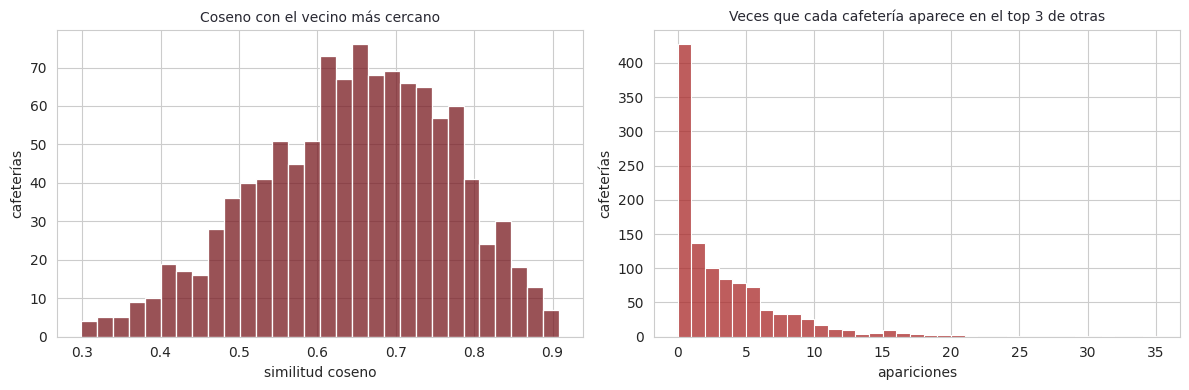

In [39]:
sim = rec.embeddings_lugar @ rec.embeddings_lugar.T
ranking = sim * rec.confianza[None, :]
np.fill_diagonal(ranking, -np.inf)
vecinos = np.argsort(-ranking, axis=1)[:, :3]
apariciones = np.bincount(vecinos.ravel(), minlength=len(sim))
top1 = sim[np.arange(len(sim)), vecinos[:, 0]]

print(f'Coseno del vecino más cercano: mediana {np.median(top1):.2f} (mín. {top1.min():.2f}, máx. {top1.max():.2f})')
print(f'Vecinos de la misma marca: {misma_marca[np.arange(len(sim))[:, None], vecinos].mean():.1%} '
      f'(al azar se esperaría {base_marca:.1%})')
print(f'Cafeterías que nunca aparecen en un top 3: {(apariciones == 0).mean():.1%} '
      f'| máximo de apariciones de una sola: {apariciones.max()}')
print(f'Vecinos con baja confianza en los top 3: {(rec.confianza[vecinos] < 1).mean():.1%} '
      f'(las de baja confianza son {(rec.confianza < 1).mean():.1%} del total)')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(top1, bins=30, color=color2, ax=axes[0])
axes[0].set_title('Coseno con el vecino más cercano', color=color1, fontsize=10)
axes[0].set_xlabel('similitud coseno')
sns.histplot(apariciones, bins=range(0, apariciones.max() + 2), color=color3, ax=axes[1])
axes[1].set_title('Veces que cada cafetería aparece en el top 3 de otras', color=color1, fontsize=10)
axes[1].set_xlabel('apariciones')
for ax in axes:
    ax.set_ylabel('cafeterías')
plt.tight_layout()
plt.show()

### Función 2: de características a cafeterías

Mismas 16 consultas y misma métrica de la sección 6, ahora con la clase `Recomendador`, con y sin la ponderación por
número de reseñas.

P@10 media con ponderación: 0.61 | sin ponderar: 0.44 | tasa base media: 0.14 | lift medio: 5.63
Consultas sin ningún acierto en el top 10: 1 de 16


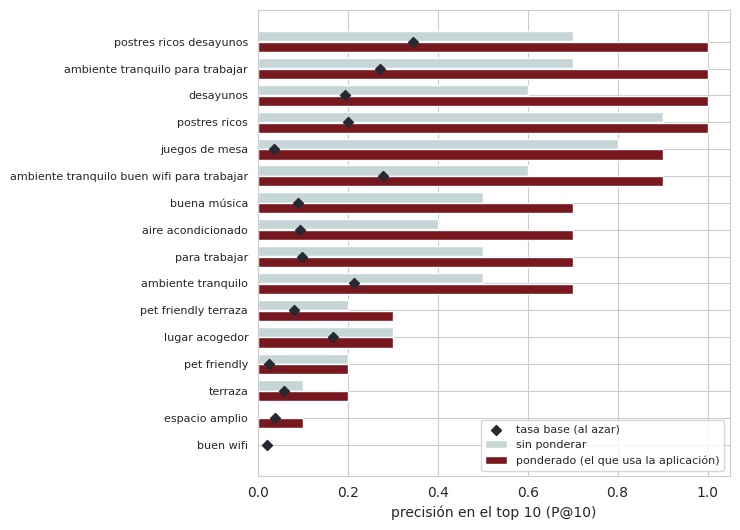

,consulta,tasa base,P@5,P@10,lift P@10,P@10 sin ponderar,baja conf. top-10 sin pond.,baja conf. top-10 pond.
0,ambiente tranquilo,0.21,0.8,0.7,3.27,0.5,5,0
1,para trabajar,0.10,0.6,0.7,7.13,0.5,3,0
2,buen wifi,0.02,0.0,0.0,0.00,0.0,2,0
3,pet friendly,0.03,0.2,0.2,7.94,0.2,1,0
4,postres ricos,0.20,1.0,1.0,5.00,0.9,1,0
5,aire acondicionado,0.09,0.8,0.7,7.48,0.4,5,0
6,juegos de mesa,0.04,1.0,0.9,25.00,0.8,1,0
7,terraza,0.06,0.2,0.2,3.47,0.1,6,0
8,desayunos,0.19,1.0,1.0,5.17,0.6,5,0
9,lugar acogedor,0.17,0.4,0.3,1.79,0.3,4,0


In [40]:
filas = []
for (consulta, _), relevante in zip(CONSULTAS, relevantes):
    cos = rec.cosenos_por_texto(consulta)
    pond = np.argsort(-(cos * rec.confianza))
    crudo = np.argsort(-cos)
    filas.append({
        'consulta': consulta, 'tasa base': relevante.mean(),
        'P@5': relevante[pond[:5]].mean(), 'P@10': relevante[pond[:10]].mean(),
        'lift P@10': relevante[pond[:10]].mean() / relevante.mean(),
        'P@10 sin ponderar': relevante[crudo[:10]].mean(),
        'baja conf. top-10 sin pond.': int((rec.confianza[crudo[:10]] < 1).sum()),
        'baja conf. top-10 pond.': int((rec.confianza[pond[:10]] < 1).sum()),
    })
resultado_f2 = pd.DataFrame(filas)
print(f"P@10 media con ponderación: {resultado_f2['P@10'].mean():.2f} | sin ponderar: "
      f"{resultado_f2['P@10 sin ponderar'].mean():.2f} | tasa base media: {resultado_f2['tasa base'].mean():.2f} "
      f"| lift medio: {resultado_f2['lift P@10'].mean():.2f}")
print(f"Consultas sin ningún acierto en el top 10: {int((resultado_f2['P@10'] == 0).sum())} de {len(resultado_f2)}")

orden = resultado_f2.sort_values('P@10').reset_index(drop=True)
y = np.arange(len(orden))
fig, ax = plt.subplots(figsize=(7.5, 5.4))
ax.barh(y + 0.2, orden['P@10 sin ponderar'], height=0.38, color=color4, label='sin ponderar')
ax.barh(y - 0.2, orden['P@10'], height=0.38, color=color2, label='ponderado (el que usa la aplicación)')
ax.scatter(orden['tasa base'], y, marker='D', s=26, color=color1, zorder=3, label='tasa base (al azar)')
ax.set_yticks(y)
ax.set_yticklabels(orden['consulta'], fontsize=8)
ax.set_xlim(0, 1.05)
ax.set_xlabel('precisión en el top 10 (P@10)')
ax.legend(loc='lower right', fontsize=8, frameon=True)
plt.tight_layout()
plt.show()
resultado_f2.round(2)

In [41]:
# Revisión a mano: top 5 de algunas consultas y cuántas reseñas de cada cafetería mencionan el tema
for consulta, patron in [CONSULTAS[0], CONSULTAS[2], CONSULTAS[3], CONSULTAS[12]]:
    m = menciones_por_lugar(patron)
    print(f'Consulta: "{consulta}"')
    print(pd.DataFrame([{'nombre': r['nombre'], 'score': r['score_similitud'], 'n_texto': r['n_resenas_texto'],
                         'menciones': int(m[rec._indice[r['place_id']]])}
                        for r in rec.recomendar_por_texto(consulta, top_k=5)]).to_string(index=False))
    print()

Consulta: "ambiente tranquilo"
                          nombre  score  n_texto  menciones
         Starbucks Paseo Montejo 0.6535       25          2
Raffaella Caffe By Dolce Delizia 0.6250       13          6
           Savarino Galeria Cafe 0.6239       25          3
    Sala De Fiestas “El Cielito” 0.6112        7          1
           Sempere Libros y Café 0.6073       25          9

Consulta: "buen wifi"
                         nombre  score  n_texto  menciones
Snoopy Frapp Frappes del parque 0.5512        7          0
   Sala De Fiestas “El Cielito” 0.5463        7          0
           Modulo 3 Paseo Verde 0.5272       17          0
                      Starbucks 0.5263       25          1
      Joa’s Coffee Mérida Norte 0.5251        7          0

Consulta: "pet friendly"
                          nombre  score  n_texto  menciones
                    Caneroll MID 0.6498        7          0
Raffaella Caffe By Dolce Delizia 0.6161       13          1
                    El Tio

In [42]:
# Efecto de la ponderación en una consulta
consulta = 'ambiente tranquilo para trabajar'
cos = rec.cosenos_por_texto(consulta)


def tabla_top(orden):
    """Top 10 con número de reseñas con texto, coseno y confianza de cada cafetería."""
    return pd.DataFrame({'nombre': [rec.cafeterias[i]['nombre'] for i in orden],
                         'n_texto': [rec.cafeterias[i]['n_resenas_texto'] for i in orden],
                         'coseno': cos[orden].round(3), 'confianza': rec.confianza[orden].round(2)})


print(f'Consulta: "{consulta}"\n\nSin ponderar:')
print(tabla_top(np.argsort(-cos)[:10]).to_string(index=False))
print('\nPonderado (el que usa la aplicación):')
print(tabla_top(np.argsort(-(cos * rec.confianza))[:10]).to_string(index=False))

Consulta: "ambiente tranquilo para trabajar"

Sin ponderar:
                          nombre  n_texto  coseno  confianza
                   Temazate Café        1   0.779        0.2
                 The coffee belt       10   0.655        1.0
         Starbucks Paseo Montejo       25   0.639        1.0
                   COFFE Y BITES        3   0.612        0.6
               Montino Cafetería        1   0.584        0.2
                           Bimbo        2   0.582        0.4
         Starbucks Harbor Mérida       25   0.582        1.0
Starbucks Urban Center Mérida DT       25   0.580        1.0
                       Starbucks       25   0.573        1.0
              Kukulcán Cafetería       25   0.564        1.0

Ponderado (el que usa la aplicación):
                          nombre  n_texto  coseno  confianza
                 The coffee belt       10   0.655        1.0
         Starbucks Paseo Montejo       25   0.639        1.0
         Starbucks Harbor Mérida       25   0.5

### Precisión de cada característica del panel

In [43]:
filas = []
for tag, patron in TAGS.items():
    relevante = menciones_por_lugar(patron) >= 2
    top10 = np.argsort(-(rec.cosenos_por_texto(tag) * rec.confianza))[:10]
    filas.append({'característica': tag, 'reseñas que la mencionan': int(menciones[:, col_tag[tag]].sum()),
                  'cafeterías con >= 2 menciones': int(relevante.sum()), 'tasa base': relevante.mean(),
                  'P@10': relevante[top10].mean(), 'lift': relevante[top10].mean() / relevante.mean()})
precision_tags = pd.DataFrame(filas).sort_values('cafeterías con >= 2 menciones', ascending=False).reset_index(drop=True)
print(f"P@10 media: {precision_tags['P@10'].mean():.2f} | tasa base media: {precision_tags['tasa base'].mean():.2f} "
      f"| características con P@10 de al menos 0.5: {int((precision_tags['P@10'] >= 0.5).sum())} de {len(precision_tags)}")
precision_tags.round(2)

P@10 media: 0.62 | tasa base media: 0.12 | características con P@10 de al menos 0.5: 14 de 20


,característica,reseñas que la mencionan,cafeterías con >= 2 menciones,tasa base,P@10,lift
0,servicio amable,3000,574,0.52,1.0,1.94
1,ambiente tranquilo,866,238,0.21,0.7,3.27
2,postres ricos,1123,222,0.20,1.0,5.00
3,desayunos,1079,215,0.19,1.0,5.17
4,panadería,912,195,0.18,1.0,5.70
5,lugar acogedor,728,186,0.17,0.3,1.79
6,servicio rápido,717,177,0.16,0.8,5.02
7,decoración bonita,586,142,0.13,0.8,6.26
8,para trabajar,485,109,0.10,0.7,7.13
9,aire acondicionado,456,104,0.09,0.7,7.48


### Longitud de las reseñas y mapa de las cafeterías

El modelo de *embeddings* procesa como máximo 128 *tokens* por texto. El mapa en 2 dimensiones (PCA a 50
componentes y t-SNE) solo sirve para ver agrupaciones, ya que t-SNE deforma las distancias.

In [44]:
ids = modelo.tokenizer(resenas_texto['review_text_limpio'].tolist(), add_special_tokens=True, truncation=False)['input_ids']
tokens = np.array([len(x) for x in ids])
truncadas = tokens > modelo.max_seq_length
print(f'Tokens por reseña: mediana {np.median(tokens):.0f} | percentil 95 {np.percentile(tokens, 95):.0f} '
      f'| máximo {tokens.max()}')
print(f'Reseñas que superan el límite de {modelo.max_seq_length} tokens y se truncan: {truncadas.sum()} '
      f'de {len(tokens)} ({truncadas.mean():.1%})')

Tokens por reseña: mediana 38 | percentil 95 148 | máximo 971
Reseñas que superan el límite de 128 tokens y se truncan: 1099 de 15685 (7.0%)


Fidelidad local del mapa (trustworthiness, 10 vecinos): 0.95
Starbucks: 26 cafeterías | vecinos de la misma cadena entre los 5 más cercanos del mapa: 69% (al azar: 2.3%)
The Italian Coffee: 11 cafeterías | vecinos de la misma cadena entre los 5 más cercanos del mapa: 38% (al azar: 1.0%)
Dunkin': 9 cafeterías | vecinos de la misma cadena entre los 5 más cercanos del mapa: 27% (al azar: 0.8%)
Sentimiento medio de las 46 sucursales de estas cadenas: 3.25 | resto: 4.41


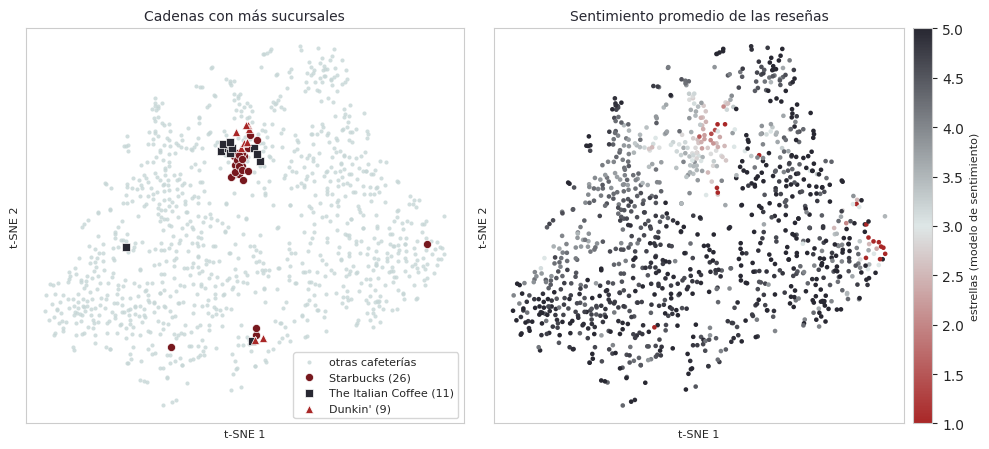

In [45]:
X = rec.embeddings_lugar
X50 = PCA(n_components=50, random_state=SEMILLA).fit_transform(X)
XY = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=SEMILLA).fit_transform(X50)
print(f'Fidelidad local del mapa (trustworthiness, 10 vecinos): {trustworthiness(X, XY, n_neighbors=10):.2f}')

CADENAS = {'starbucks': ('Starbucks', color2, 'o'), 'italian': ('The Italian Coffee', color1, 's'),
           'dunkin': ("Dunkin'", color3, '^')}
vecinos_mapa = NearestNeighbors(n_neighbors=6).fit(XY).kneighbors(XY, return_distance=False)[:, 1:]
for clave, (nombre, _, _) in CADENAS.items():
    es = marcas == clave
    print(f'{nombre}: {es.sum()} cafeterías | vecinos de la misma cadena entre los 5 más cercanos del mapa: '
          f'{es[vecinos_mapa[es]].mean():.0%} (al azar: {es.mean():.1%})')

sent_lugar = np.array([np.nan if c['sentimiento_promedio'] is None else c['sentimiento_promedio']
                       for c in rec.cafeterias], dtype=float)
es_cadena = np.isin(marcas, list(CADENAS))
print(f'Sentimiento medio de las {es_cadena.sum()} sucursales de estas cadenas: {np.nanmean(sent_lugar[es_cadena]):.2f} '
      f'| resto: {np.nanmean(sent_lugar[~es_cadena]):.2f}')

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
axes[0].scatter(XY[~es_cadena, 0], XY[~es_cadena, 1], s=9, color=color4, alpha=0.8, linewidths=0,
                label='otras cafeterías')
for clave, (nombre, color, marcador) in CADENAS.items():
    es = marcas == clave
    axes[0].scatter(XY[es, 0], XY[es, 1], s=34, color=color, marker=marcador, edgecolors='white', linewidths=0.5,
                    label=f'{nombre} ({es.sum()})')
axes[0].set_title('Cadenas con más sucursales', color=color1, fontsize=10)
axes[0].legend(fontsize=8, loc='best', frameon=True)
puntos = axes[1].scatter(XY[:, 0], XY[:, 1], c=sent_lugar, vmin=1, vmax=5, s=11, linewidths=0,
                         cmap=LinearSegmentedColormap.from_list('sentimiento', [color3, color5, color1]))
axes[1].set_title('Sentimiento promedio de las reseñas', color=color1, fontsize=10)
fig.colorbar(puntos, ax=axes[1], fraction=0.046, pad=0.02).set_label('estrellas (modelo de sentimiento)', fontsize=8)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('t-SNE 1', fontsize=8)
    ax.set_ylabel('t-SNE 2', fontsize=8)
plt.tight_layout()
plt.show()

### Guardado del modelo y ejemplo de uso

El artefacto se guarda con `joblib` en `salidas/` y se vuelve a cargar para confirmar que da los mismos resultados.

In [46]:
artefacto['metadatos'] = {
    'creado': date.today().isoformat(),
    'n_cafeterias': len(place_ids),
    'n_resenas_embebidas': int(len(resenas_texto)),
    'vectores_funcion_1': 'centrados',
    'vectores_funcion_2': 'sin centrar, con plantilla de consulta',
    'ponderacion': 'score = coseno * min(1, n_resenas_texto / min_resenas_confiable)',
    'versiones': {'python': sys.version.split()[0], 'numpy': np.__version__, 'torch': torch.__version__},
}
RUTA_ARTEFACTO = SALIDAS / 'recomendador.joblib'
joblib.dump(artefacto, RUTA_ARTEFACTO, compress=3)

rec_disco = Recomendador.cargar(RUTA_ARTEFACTO, modelo_texto=modelo)
pid_prueba = buscar('Starbucks Paseo Montejo')
assert rec_disco.recommend(pid_prueba, 3, 'place') == rec.recommend(pid_prueba, 3, 'place')
assert rec_disco.recommend('ambiente tranquilo', 10, 'text') == rec.recommend('ambiente tranquilo', 10, 'text')
print(f'Guardado: {RUTA_ARTEFACTO.as_posix()} ({RUTA_ARTEFACTO.stat().st_size / 1e6:.1f} MB); '
      f'el modelo cargado da los mismos resultados.')

Guardado: salidas/recomendador.joblib (3.3 MB); el modelo cargado da los mismos resultados.


In [47]:
def mostrar(resultados):
    """Campos que muestra la tarjeta de la aplicación para cada resultado."""
    return pd.DataFrame(resultados)[['nombre', 'rating', 'sentimiento', 'atributos', 'baja_confianza', 'score_similitud']]


print('Función 1: cafeterías similares a Marmalade Centro')
display(mostrar(rec.recommend(buscar('Marmalade Centro'), 3, 'place')))
print('Función 2: características "ambiente tranquilo" y "para trabajar"')
display(mostrar(rec.recommend('ambiente tranquilo para trabajar', 5, 'text')))

Función 1: cafeterías similares a Marmalade Centro


,nombre,rating,sentimiento,atributos,baja_confianza,score_similitud
0,Marmalade Luxury,4.8,Positivo,"[desayunos, servicio amable, panadería]",False,0.7658
1,Alma piedra - Temozón,4.8,Positivo,"[desayunos, servicio amable, servicio rápido]",False,0.7619
2,La Libertad García Lavín | Desayunos & Brunch Mérida Yucatán,4.7,Positivo,"[desayunos, panadería, decoración bonita]",False,0.7367


Función 2: características "ambiente tranquilo" y "para trabajar"


,nombre,rating,sentimiento,atributos,baja_confianza,score_similitud
0,The coffee belt,4.8,Positivo,"[para trabajar, ambiente tranquilo, servicio rápido]",False,0.6553
1,Starbucks Paseo Montejo,4.5,Positivo,"[aire acondicionado, para trabajar, terraza]",False,0.6386
2,Starbucks Harbor Mérida,4.5,Neutro,"[aire acondicionado, ambiente tranquilo, pet friendly]",False,0.5821
3,Starbucks Urban Center Mérida DT,4.4,Neutro,"[aire acondicionado, estacionamiento, servicio rápido]",False,0.5795
4,Starbucks,4.5,Neutro,"[estacionamiento, para trabajar, aire acondicionado]",False,0.5733


## 8. Conclusiones y recomendaciones

Se construyó un recomendador de cafeterías para Mérida que se basa en lo que expresan sus clientes en las reseñas.
El contexto lo da el DENUE: el código de cafeterías, fuentes de sodas y neverías (722515) creció 9.9% entre 2024 y
2026, frente a 4.7% del resto del subsector de alimentos y bebidas, y se compone en su mayoría de micronegocios. Para
el modelo se reunieron 1,619 cafeterías con Google Places y 17,422 reseñas de Google Maps, se depuraron y analizaron
los datos, y se desarrolló un recomendador, sustentado en un modelo de lenguaje preentrenado y en la similitud del
coseno, que ofrece dos funciones: encontrar las cafeterías más similares a una dada y encontrar las que mejor
responden a una combinación de características. El modelo se puso a disposición en la aplicación web Locus.

**Hallazgos principales**

- **La calificación distingue poco entre cafeterías.** 73.8% de los lugares tiene 4.5 o más y 77.2% de las reseñas
  son de cinco estrellas, por lo que ordenar por calificación aporta poca información y se justifica recomendar por
  el contenido de las reseñas.
- **El texto aporta información que la calificación no captura.** El sentimiento promedio de las reseñas se
  relaciona con la calificación (correlación de 0.77), pero en algunos lugares se separa de ella, como en las 46
  sucursales de Starbucks, The Italian Coffee y Dunkin', cuyo sentimiento medio es de 3.25 estrellas frente a 4.41
  del resto.
- **El parecido entre reseñas funciona para los temas frecuentes.** La búsqueda por características alcanza una
  precisión de 0.61 en los diez primeros resultados frente a 0.14 de un orden al azar, y 14 de las 20
  características llegan a 0.5 o más. En los temas poco frecuentes, como el wifi, la precisión es baja.
- **Las decisiones de diseño se sustentaron en datos.** Centrar los vectores corrigió la escala de la Función 1, la
  plantilla de la consulta elevó la precisión de la Función 2 de 0.38 a 0.61 y la ponderación por número de reseñas
  evitó que las cafeterías con pocas reseñas ocuparan los primeros lugares.

**Impacto para la toma de decisiones**

- **Para la persona que busca una cafetería.** Conviene elegir por el tipo de experiencia y no por la calificación, y
  revisar cuántas reseñas la respaldan: en la cuarta parte de los lugares con menos reseñas la calificación mediana
  es 5.0, y en la cuarta parte con más reseñas es 4.6.
- **Para los dueños de cafeterías.** Las quejas más frecuentes en las reseñas negativas se refieren al servicio
  (*pésimo servicio*, *mal servicio*, *media hora*), por lo que la atención y los tiempos de espera son la prioridad.
  Asimismo, servicios como el wifi, la terraza o la admisión de mascotas casi no se mencionan en las reseñas, y las
  cafeterías con menos de cinco reseñas con texto casi nunca aparecen entre los primeros resultados; dar a conocer
  esos servicios y pedir reseñas escritas mejora su visibilidad.
- **Para Geometra.** Se requiere ampliar y actualizar la base de reseñas (340 cafeterías tienen menos de cinco con
  texto y 508 no tienen ninguna) y mejorar la búsqueda de las características poco frecuentes. La cantidad de
  cafeterías por zona indica cuánta oferta hay, pero no cuántos clientes, por lo que no basta para decidir dónde
  abrir un negocio.

**Limitaciones**

El desempeño se considera satisfactorio para los temas frecuentes y limitado para los poco frecuentes. La evaluación
tiene un alcance acotado: mide menciones de palabras y no la satisfacción de las personas, y no se realizaron
pruebas con usuarios, por lo que todavía no es posible afirmar la utilidad de la aplicación en el uso real.
Adicionalmente, el modelo solo puede recomendar las 1,111 cafeterías con reseñas con texto, y las que tienen menos de
cinco reseñas con texto casi no aparecen en los resultados. Los datos describen la oferta y las reseñas, y no la
demanda, por lo que no permiten estimar ingresos de un servicio de este tipo.

**Sugerencias para mejoras futuras**

- **Probar la aplicación con personas.** Una prueba con pocas personas y tareas definidas (encontrar una cafetería
  parecida a una conocida y encontrar un lugar para trabajar), en la que se registren los tiempos, los errores y las
  dudas.
- **Mejorar las características poco frecuentes.** Comparar la agregación por reseña, que en una prueba preliminar
  mejoró algunas de ellas, con el promedio de *embeddings* actual, y probar otros modelos de *embeddings*
  multilingües.
- **Ampliar los datos.** Extraer más de 25 reseñas por lugar, actualizarlas de forma periódica y agregar la colonia
  de cada cafetería.
- **Explorar el agrupamiento.** Aplicar un algoritmo de *clustering* para describir tipos de cafeterías, lo que en
  este trabajo no fue necesario para recomendar.
- **Desarrollar la línea para negocios.** Analizar el posicionamiento de una cafetería frente a sus competidoras más
  parecidas y la evolución de sus reseñas, con el mismo modelo.